In [2]:
%reset -f
%matplotlib inline
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
plt.rcParams['figure.facecolor'] = 'white'

import os, glob

import numpy as np

from tqdm.auto import tqdm

from astropy.table import Table, vstack
from astropy.time import Time, TimeDelta
from astropy import units as u
from astropy.coordinates import SkyCoord, concatenate

import requests
import pandas as pd
pd.set_option('display.max_columns', None)

import io

# import pickle

# from fastparquet import ParquetFile

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
# TNS

In [3]:
import io
import requests

r = requests.post(
    'https://api.fink-portal.org/api/v1/resolver',
    json={
        'resolver': 'tns',
        'name': '',
        'nmax': 1000000
    }
)
tns = pd.read_json(io.BytesIO(r.content))
print(len(tns), 'TNS entries')

tns_tdes = tns[[_.startswith('TDE') and __.startswith('ZTF') for _,__ in zip(tns['d:type'], tns['d:internalname'])]]
tns_tdes = tns_tdes['d:internalname'].drop_duplicates().values
print(len(tns_tdes), 'unique TDEs')

247671 TNS entries
114 unique TDEs


In [4]:
tns_tdes = tns[[_.startswith('TDE') and __.startswith('ZTF') for _,__ in zip(tns['d:type'], tns['d:internalname'])]]
tns_tdes = tns_tdes['d:internalname'].drop_duplicates().values.astype(str)
print(len(tns_tdes), 'TDEs')

tns_nontdes = tns[[not _.startswith('TDE') and _ != 'nan' and __.startswith('ZTF') for _,__ in zip(tns['d:type'], tns['d:internalname'])]]
tns_nontdes = tns_nontdes['d:internalname'].drop_duplicates().values.astype(str)
print(len(tns_nontdes), 'non-TDEs')

109 TDEs
12851 non-TDEs


In [5]:
tns_types = tns[['d:internalname', 'd:fullname', 'd:type']]
tns_types = tns_types[[_.startswith('ZTF') for _ in tns_types['d:internalname'].values]]
tns_types.rename(columns={'d:internalname': 'objectId', 'd:fullname': 'tns_name', 'd:type': 'tns'}, inplace=True)
tns_types = tns_types.drop_duplicates('objectId')

In [6]:
def get_tns_info(oid=None, ra=None, dec=None, sr=5/3600):
    result = []
    
    if oid is not None:
        idx = (tns['d:internalname'] == oid) | (tns['d:fullname'] == oid)
    elif ra is not None and dec is not None:
        idx = SkyCoord(tns['d:ra'].values, tns['d:declination'].values, unit='deg').separation(SkyCoord(ra, dec, unit='deg')).deg < sr
    else:
        return None
    
    for i,row in tns[idx].iterrows():
        res = row['d:fullname']
        if row['d:type'] and row['d:type'] != 'nan':
            res += ' (' + row['d:type']
            if row['d:redshift'] > 0:
                res += f" z={row['d:redshift']}"
            res += ')'
            
        if res not in result:
            result.append(res)
        
    return " | ".join(result)

get_tns_info('ZTF20acxfcmr')

'AT 2020accc'

In [7]:
tns

,d:declination,d:fullname,d:internalname,d:ra,d:redshift,d:type
0,-55.409677,AT 1976S,GSC2.3 SATX032616,286.245594,NaN,nan
1,-25.480611,AT 1978M,GSC2.3 S64P036598,122.320327,NaN,nan
2,29.127500,AT 1989am,LANAT-SN-1,236.939542,NaN,nan
3,47.530987,AT 1991bm,GSC2.3 N0ZY037003,273.810015,NaN,nan
4,14.414089,AT 1992bw,GSC2.3 NB6I007107,1.510637,NaN,nan
...,...,...,...,...,...,...
236069,8.905047,TDE 2025kkj,ZTF25aaptkov,222.969079,0.2920,TDE
236070,52.320982,TDE 2025lxx,ZTF25aaplxiz,237.404978,0.1450,TDE-He
236071,-4.991182,TDE 2025ug,ATLAS25axz,160.126969,0.1331,TDE
236072,-4.991182,TDE 2025ug,GOTO25qp,160.126969,0.1331,TDE


In [8]:
# FLEET dataset - https://iopscience.iop.org/article/10.3847/1538-4357/acc535

fleet = []

for line in """
AT2021crk 0.97 
AT2021ldl 0.80 
AT2020kri 0.67 
AT2020aexc 0.58 
AT2019gtm 0.97 
AT2020ygl 0.80 
AT2021pqg 0.66 
AT2021qbh 0.57 
AT2021aees 0.91 
AT2019zbt 0.80 
AT2018jil 0.66 
AT2020afap 0.57 
AT2021aeuf 0.90 
AT2021zvy 0.72 
AT2021uhs 0.64 
AT2019aamf 0.57 
AT2021lsi 0.86 
AT2021ony 0.71 
AT2021xbz 0.63 
AT2021abkx 0.56 
AT2020bgf 0.86 
AT2020qfm 0.71 
AT2021acqt 0.63 
AT2019enj 0.56 
AT2021kqp 0.85 
AT2019phf 0.71 
AT2019aami 0.62 
AT2021aux 0.52 
AT2021wdh 0.82 
AT2021icq 0.70 
AT2021nhq 0.61 
AT2020qmx 0.51 
AT2021iqs 0.82 
AT2019qdh 0.70 
AT2019saj 0.60 
AT2020aawn 0.50 
AT2020dxw 0.81 
AT2019wlv 0.69 
AT2020nmc 0.5
""".splitlines():
    if line:
        s = line.split()
        row = {'tns_name': s[0].replace('AT', 'AT '), 'proba': float(s[1]), 'objectId': ''}
        
        idx = tns['d:fullname'].values == row['tns_name']
        if np.sum(idx):
            row['ra'] = tns['d:ra'].values[idx][0]
            row['dec'] = tns['d:declination'].values[idx][0]
            row['tns'] = tns['d:type'].values[idx][-1]
            
            idx2 = [_.startswith('ZTF') for _ in tns['d:internalname'].values[idx]]
            if np.sum(idx2):
                row['objectId'] = tns['d:internalname'].values[idx][idx2][0]
            
        fleet.append(row)

fleet = Table(fleet)
fleet

tns_name,proba,objectId,ra,dec,tns
str11,float64,str12,float64,float64,str3
AT 2021crk,0.97,ZTF21aakfqwq,176.278955216,18.5403591039,TDE
AT 2021ldl,0.8,ZTF21aaxtlvc,202.97779234,3.90106493815,nan
AT 2020kri,0.67,,322.403833,18.131119,nan
AT 2020aexc,0.58,ZTF21aabgjcz,181.806079,44.171,nan
AT 2019gtm,0.97,ZTF19aavwtcb,175.2383998,-2.286096,nan
AT 2020ygl,0.8,ZTF20aclgfji,138.3003129,5.1345564,nan
AT 2021pqg,0.66,,235.595136048,-7.7206400817,nan
AT 2021qbh,0.57,ZTF21abgjynw,327.753755425,31.190206925,nan
AT 2021aees,0.91,ZTF21acojhgu,155.692745514,30.5717460976,nan


In [9]:
tns_types

,objectId,tns_name,tns
45,ZTF18aarboos,AT 2013iu,nan
202,ZTF18aaaluzq,AT 2016acf,nan
369,ZTF19aabyoce,AT 2016ajv,nan
444,ZTF18acecpja,AT 2016amu,nan
720,ZTF19aangfld,AT 2016axq,nan
...,...,...,...
235660,ZTF25aauvber,SN 2025ngs,SN II
235666,ZTF25aavcgfk,SN 2025nmr,SN II
235770,ZTF25aacxidm,SN 2025yn,SN II
235778,ZTF25aacljcu,SN 2025yz,SN Ia


In [10]:
tns[idx]

,d:declination,d:fullname,d:internalname,d:ra,d:redshift,d:type
57856,3.386518,AT 2020nmc,PS20elv,225.736962,NaN,nan


# Dataset with upper limits and bad quality data

In [11]:
# data = pd.read_parquet('/home/karpov/fink/tde/tde_objects_all_withupperlim_min5_1.parquet')
data = pd.read_parquet('/home/lmiguel/gitlab_projects/TDE classification/tde_classification/data/input/tde_objects_all_withupperlim_min5_1.parquet')

print(len(data), 'light curves')

603216 light curves


In [12]:
data = data.join(tns_types.set_index('objectId'), on='objectId')

In [13]:
# More robust, positional association, as often we do not have ZTF name listed there...

from stdpipe import astrometry # TODO: directly embed the function here

ids1,ids2,dist = astrometry.spherical_match(tns['d:ra'], tns['d:declination'], data['i:ra'], data['i:dec'], 5/3600)

# TODO: fix that stupid pandas warning
data['tns_name'][ids2] = tns['d:fullname'][ids1]
data['tns'][ids2] = tns['d:type'][ids1]

/tmp/ipykernel_736632/4237339328.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['tns_name'][ids2] = tns['d:fullname'][ids1]
/tmp/ipykernel_736632/4237339328.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['tns'][ids2] = tns['d:type'][ids1]


In [14]:
tns_tdes = list(set(tns_tdes) | set(data['objectId'][[_.startswith('TDE') for _ in data['tns'].values.astype(str)]]))
print(len(tns_tdes), 'TDEs')


115 TDEs


In [15]:
idx = data['tns'].astype(str) != 'nan'
idx &= [not _.startswith('TDE') for _ in data['tns'].values.astype(str)]
tns_nontdes = list(set(tns_nontdes) | set(data['objectId'][idx]))
print(len(tns_nontdes), 'non-TDEs')

13273 non-TDEs


/tmp/ipykernel_736632/1460841499.py:2: FutureWarning: Logical ops (and, or, xor) between Pandas objects and dtype-less sequences (e.g. list, tuple) are deprecated and will raise in a future version. Wrap the object in a Series, Index, or np.array before operating instead.
  idx &= [not _.startswith('TDE') for _ in data['tns'].values.astype(str)]


In [16]:
idx = data['tns_name'].astype(str) != 'nan'
tns_all = list(set(data['objectId'][idx]))
print(len(tns_all), 'total TNS')

31307 total TNS


In [17]:
# Fleet
ids1,ids2,dist = astrometry.spherical_match(data['i:ra'], data['i:dec'], fleet['ra'], fleet['dec'], 5/3600)

fleet['objectId'][ids2] = data['objectId'][ids1]

# Nearests, as a separate table

In [ ]:
# nearests = pd.read_parquet('/home/karpov/fink/tde/nearests_all_5.parquet')
# nearests.loc[nearests['distnr_g']<0, 'distnr_g'] = np.nan
# nearests.loc[nearests['distnr_r']<0, 'distnr_r'] = np.nan
# # nearests['distnr'] = np.nanmin([nearests['distnr_g'], nearests['distnr_r']], axis=0)



# Aux functions

In [18]:
from matplotlib.colors import LinearSegmentedColormap

COLORS_ZTF = {1: "#15284F", 2: "#F5622E", 3: "#3C8DFF", 4: "#D5D5D3"}

fink_colormap = LinearSegmentedColormap.from_list('fink-3colors', [COLORS_ZTF[1], COLORS_ZTF[3], COLORS_ZTF[2]])

In [19]:
def get_lc(row):
    # Extract light curve from the data row
    pdf = pd.DataFrame({_: row[_] for _ in ['i:fid', 'i:jd', 'i:magpsf', 'i:sigmapsf', 'i:isdiffpos', 'FLUXCAL', 'FLUXCALERR']})
    
    if 'i:diffmaglim' in row:
        pdf['i:diffmaglim'] = row['i:diffmaglim']
        pdf['FLUXCALUPPER'] = 10**(11 - 0.4*pdf['i:diffmaglim'])
    
    pdf['i:mjd'] = pdf['i:jd'] - 2400000.5
    pdf.sort_values('i:jd', inplace=True, ignore_index=True)
    
    # Remove other bands?..
    pdf = pdf[(pdf['i:fid'] == 1) | (pdf['i:fid'] == 2)]
    
    return pdf

def plot_lc(pdf, show_zero=False, show_limits=False, ms=None):
    for fid,c in [(1, COLORS_ZTF[1]), (2, COLORS_ZTF[2])]:
        idx = pdf['i:fid'] == fid
        mjd = pdf['i:jd'] - 2400000.5
        
        plt.errorbar(mjd[idx], pdf['FLUXCAL'][idx], pdf['FLUXCALERR'][idx], fmt='.', c=c, alpha=0.2)
        plt.plot(mjd[idx], pdf['FLUXCAL'][idx], '.', color=c, alpha=1, ms=ms)

        if show_limits and 'FLUXCALUPPER' in pdf:
            idx &= ~np.isfinite(pdf['FLUXCAL'])
            plt.plot(mjd[idx], pdf['FLUXCALUPPER'][idx], '^', alpha=0.3, color=c)

    plt.grid(alpha=0.2)
    if show_zero:
        plt.axhline(0, ls='--', color='black', alpha=0.2)

In [20]:
def get_slope(x, y, dy):
    x = np.atleast_1d(x)
    y = np.atleast_1d(y)
    dy = np.atleast_1d(dy)
    
    idx = np.isfinite(x) & np.isfinite(y) & np.isfinite(dy)
    
    if len(x[idx]) < 3 or np.ptp(x[idx]) == 0:
        return 0,0
    
    p,cov = np.polyfit(
        x[idx] - np.mean(x[idx]), 
        y[idx] - np.mean(y), 
        1, w=1/dy[idx], cov='unscaled'
    )
    dp = np.sqrt(np.diag(cov))
    
    return p[0], dp[0]

def is_rising(jd, flux, fluxerr, fid, upper=None, nsigmas_rise=2, nsigmas_decay=1, nsigmas_slope=3, use_slope=True, verbose=False):
    idx0 = flux == flux

    is_decay = False
    is_rise = False
    
    for fid1 in [1, 2]:
        idx = idx0 & (fid == fid1)
        uidx = ~idx0 & (fid == fid1)
        if np.sum(idx) < 2:
            continue

        # Last point is significantly lower than the max?..
        diff = flux[idx][:-1] - flux[idx][-1]
        differr = np.hypot(fluxerr[idx][:-1], fluxerr[idx][-1])

        if np.any(diff > nsigmas_decay*differr):
            is_decay = True

        # Last point is significantly higher than the min?..
        diff = flux[idx][-1] - flux[idx][:-1]

        if np.any(diff > nsigmas_rise*differr):
            is_rise = True
            
        if np.sum(idx) >= 3 and use_slope:
            # Slope is significantly positive?..
            slope,serr = get_slope(jd[idx], flux[idx], fluxerr[idx])
            if verbose:
                print('slope', slope, '+/-', serr)
            if slope > nsigmas_slope*serr:
                is_rise = True
            
        # Any point is significantly lower than the previous?..
        diff = flux[idx][:-1] - flux[idx][1:]
        differr = np.hypot(fluxerr[idx][:-1], fluxerr[idx][1:])

        if np.any(diff > nsigmas_decay*differr):
            is_decay = True
            
        # Last point is significantly higher than any (prior) upper limit?..
        if upper is not None and np.sum(uidx) > 0:
            diff = flux[idx][-1] - upper[uidx]
            differr = fluxerr[idx][-1]
            
            if np.any(diff > nsigmas_rise*differr):
                is_rise = True
                            
    if verbose:
        print('rise', is_rise, 'decay', is_decay)
            
    return is_rise and not is_decay

In [21]:
def cleanup_limits(sub, ignore=False):
    if ignore:
        sub = sub[np.isfinite(sub['FLUXCAL'])]  

    elif 'FLUXCALUPPER' in sub:
        mask = np.isfinite(sub['i:jd']) 

        for fid in [1,2]:
            idx1 = sub['i:fid'] == fid # Same filter
            idx2 = np.isfinite(sub['FLUXCAL']) # Detections
            
            # jd1 = np.min(sub['i:jd'][idx1 & idx2]) # First detection, same filter
            jd1 = np.min(sub['i:jd'][idx2]) # First detection, any filter
            flux1 = (sub['FLUXCAL'][sub['i:jd']==jd1]).values[0]
            idx3 = sub['i:jd'] >= jd1 - 1 # Later than first detection
            # idx3 |= sub['FLUXCALUPPER'] > flux1 # ..or above first detection?..
            idx3 |= sub['FLUXCALUPPER'] > np.nanmin(sub['FLUXCAL'][idx1]) # ..or above min flux?..

            mask[idx1 & ~idx2 & idx3] = False
            
        sub = sub[mask]
        
    else:
        # Dataset without upper limits defined
        sub = sub.assign(FLUXCALUPPER = np.nan)

    return sub

# Feature extraction

In [168]:
from light_curve.light_curve_py import RainbowFit

# Filters ZTF
filt_conv = {1: "g", 2: "r", 3: "i"}  # Conversion between filter ID (int) and filter name (str)
band_wave_aa = {"g": 4770.0, "r": 6231.0, "i": 7625.0}  # Bands in angstroms for rainbow

Av = {1: 3.681, 2: 2.635, 3: 1.944}

feature = RainbowFit.from_angstrom(
    band_wave_aa, 
    with_baseline = False,
    temperature='constant',
    bolometric='sigmoid'
)

def extract_features(sub):
    jd = sub['i:jd'].values
    flux,fluxerr = sub['FLUXCAL'].values, sub['FLUXCALERR'].values
    flux_upper = sub['FLUXCALUPPER'].values
    fluxerr_upper = sub['FLUXCALUPPER'].values/5

    idx_good = (flux == flux)
    
    band=np.array([filt_conv[_] for _ in sub['i:fid']])

    try:
        params,errors,cov = feature._eval_and_get_errors(
            t=jd, 
            m=np.where(idx_good, flux, flux_upper), 
            sigma=np.where(idx_good, fluxerr, fluxerr_upper), 
            band=band, 
            upper_mask=~idx_good, 
            return_covariance=True,
            debug=True, 
        )

        result = {}
        result['params'] = params
        result['errors'] = errors
        result['cov'] = cov
        
        return result
    except KeyboardInterrupt:
        raise
    except:
        return None

def print_features(res1):
    for i,name in enumerate(feature.names):
        value,error = res1['params'][i], res1['errors'][i]
        
        if name in ['rise_time', 'T', 'amplitude']:
            snr = f" (S/N = {value/error:.1f})"
        else:
            snr = ''
            
        if name == 'reference_time':
            value -= 2400000.5
            
        print(f"{name} = {value:.1f} +/- {error:.1f}{snr}")
    print(f"r_chisq = {res1['params'][-1]:.1f}")

def plot_features(sub, res1, nsamples=100, prior=100, jd_min=None, jd_max=None, extra=None, **kwargs):
    if jd_min is not None:
        sub = sub[sub['i:jd'] >= jd_min]
    if jd_max is not None:
        sub = sub[sub['i:jd'] <= jd_max]
        
    plot_lc(sub, **kwargs)

    if prior:
        t = np.linspace(np.max(sub['i:jd']) - prior, np.max(sub['i:jd']) + 1, 1000)
    else:
        t = np.linspace(np.min(sub['i:jd']) - 1, np.max(sub['i:jd']) + 1, 1000)

    for iter in range(nsamples):
        params1 = np.random.multivariate_normal(res1['params'][:-1], res1['cov'])
        if params1[feature.p['amplitude']] < 0:
            continue
        for fid,c,col in ((0, 'g', COLORS_ZTF[1]), (1, 'r', COLORS_ZTF[2])):
            plt.plot(
                t - 2400000.5, 
                feature.model(t, c, *params1), 
                color=col, alpha=0.03
            )

    for c,col in [('g', COLORS_ZTF[1]), ('r', COLORS_ZTF[2])]:
        plt.plot(
            t - 2400000.5,
            feature.model(t, [c], *res1['params']),
            '--', color=col, alpha=0.5
        )

    texts = []
    for i,name in enumerate(feature.names):
        value,error = res1['params'][i], res1['errors'][i]
        
        if name in ['rise_time', 'T', 'amplitude']:
            snr = f" (S/N = {value/error:.1f})"
        else:
            snr = ''
            
        if name == 'reference_time':
            value -= 2400000.5
            
        texts.append(f"{name} = {value:.1f} +/- {error:.1f}{snr}")
    texts.append(f"r_chisq = {res1['params'][-1]:.1f}")

    if extra is not None:
        texts += extra # TODO: check whether it is a list
        
    plt.text(
        0.05, 0.95, 
        "\n".join(texts), 
        transform=plt.gca().transAxes, 
        va='top', 
        bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.7}
    )

/home/karpov/.local/lib/python3.13/site-packages/light_curve/light_curve_py/warnings.py:19: ExperimentalWarning: Function light_curve.light_curve_py.features.rainbow.generic.RainbowFit is experimental and may cause any kind of troubles
  warn_experimental(message)


In [166]:
from dustmaps.sfd import SFDQuery

sfd = SFDQuery()

## Actual feature extraction from the dataset - skip for using pre-extracted features

In [190]:
get_lc(data.iloc[0])

,i:fid,i:jd,i:magpsf,i:sigmapsf,i:isdiffpos,FLUXCAL,FLUXCALERR,i:diffmaglim,FLUXCALUPPER,i:mjd
0,2,2.459053e+06,NaN,NaN,None,NaN,NaN,20.700300,524.662366,59052.418819
1,1,2.459053e+06,NaN,NaN,None,NaN,NaN,20.743401,504.242875,59052.460810
2,2,2.459054e+06,18.242001,0.202103,f,-5048.934866,939.828247,20.697300,526.114192,59053.459433
3,1,2.459056e+06,NaN,NaN,None,NaN,NaN,20.581699,585.221471,59055.419826
4,2,2.459056e+06,NaN,NaN,None,NaN,NaN,20.569599,591.780076,59055.440544
...,...,...,...,...,...,...,...,...,...,...
238,1,2.460587e+06,NaN,NaN,None,NaN,NaN,21.174000,339.156454,60586.352049
239,2,2.460587e+06,16.827600,0.051281,0,18576.325331,877.389111,21.019400,391.057071,60586.375336
240,1,2.460587e+06,NaN,NaN,None,NaN,NaN,21.064699,375.076911,60586.398692
241,2,2.460587e+06,NaN,NaN,None,NaN,NaN,20.948601,417.406966,60586.422095


In [206]:
import multiprocessing

def fn(args, window=100, hist_window=100):
    i,cand = args
    
    # Full length light curve
    pdf = get_lc(cand)
    
    # De-reddening using 
    Ebv = sfd(SkyCoord(cand['i:ra'], cand['i:dec'], unit='deg'))
    for fid in [1,2,3]:
        idx = pdf['i:fid'] == fid
        pdf.loc[idx, 'FLUXCAL'] /= 10**(-0.4*(Ebv*Av[fid]))
        pdf.loc[idx, 'FLUXCALERR'] /= 10**(-0.4*(Ebv*Av[fid]))
        pdf.loc[idx, 'FLUXCALUPPER'] /= 10**(-0.4*(Ebv*Av[fid]))
    
    results = []
    
    used = np.zeros(len(pdf), dtype=bool)
    counter = 0
    pcounter = 0
    
    # Cycle over all possible windows, starting from the latest
    for jd_max in sorted(pdf['i:jd'][np.isfinite(pdf['FLUXCAL'])], reverse=True):
        jd_min = jd_max - window
        idx0 = (pdf['i:jd'] <= jd_max) & (pdf['i:jd'] >= jd_min) # window

        # WARNING: Avoid overlaps with already used windows
        if np.any(used[idx0]):
            # continue
            pass
        else:
            pcounter = 0

        sub = pdf[idx0]
    
        # Basic cuts
        idx = np.isfinite(sub['FLUXCAL'])
        if (
            # Min length
            len(sub[idx]) < 5 or 
            # At least one point in every filter
            np.sum(idx & (sub['i:fid'] == 1)) < 1 or 
            np.sum(idx & (sub['i:fid'] == 2)) < 1 or 
            # No more than 1 negative point
            np.sum(idx & (sub['FLUXCAL'] < 0)) > 1
        ):
            continue
  
        hres = {}
        # Pre-window history        
        hist_idx = (pdf['i:jd'] <= jd_min) & (pdf['i:jd'] > jd_min - hist_window) # History window prior to the window above
        hres['num_hist_detections'] = np.sum(hist_idx & np.isfinite(pdf['FLUXCAL'])) # Detections in historical window
        hres['num_hist_limits'] = np.sum(hist_idx & ~np.isfinite(pdf['FLUXCAL'])) # Upper limits
        
        # All prior detections
        prehist_idx = (pdf['i:jd'] <= jd_min) # Everything prior to the window above
        hres['num_prehist_detections'] = np.sum(prehist_idx & np.isfinite(pdf['FLUXCAL'])) # Detections prior to window
        hres['num_prehist_negatives'] = np.sum(prehist_idx & np.isfinite(pdf['FLUXCAL']) & (pdf['FLUXCAL'] < 0)) # Negative detections prior to window
        hres['num_prehist_limits'] = np.sum(prehist_idx & ~np.isfinite(pdf['FLUXCAL'])) # Upper limits

        # Remove redundant upper limits within window
        sub = cleanup_limits(sub)
        
        # WARNING: Discard upper limits, for now!!!
        # sub = sub[np.isfinite(sub['FLUXCAL'])]  

        # Number of detections and limits
        idx = np.isfinite(sub['FLUXCAL'])
        hres['num_detections'] = np.sum(idx)
        hres['num_negatives'] = np.sum(idx & (sub['FLUXCAL'] < 0))
        hres['num_limits'] = np.sum(~idx)
    
        try:
            rise = is_rising(
                sub['i:jd'].values, 
                sub['FLUXCAL'].values, 
                sub['FLUXCALERR'].values, 
                sub['i:fid'].values, 
                # upper=sub['FLUXCALUPPER'].values, 
                verbose=False, 
                nsigmas_rise=2, 
                nsigmas_decay=1
            )
        except KeyboardInterrupt:
            raise
        except:
            print(cand['objectId'], 'failed')
            continue
            
        if not rise:
            continue

        used[idx0] = True # Mark this window as already used

        res1 = extract_features(sub)
        # Initial quality cuts for the fit
        if res1 is None or res1['params'][-1] > 10:
            continue
        
        # Fill results with fitted features
        res = {}
        res['objectId'] = cand['objectId']
        res['Ebv'] = Ebv
        res['jd_min'] = jd_min
        res['jd_max'] = jd_max

        for i,name in enumerate(feature.names):
            res[name] = res1['params'][i]
            res['e_' + name] = res1['errors'][i]
            
            if name not in ['reference_time']:
                res['snr_' + name] = np.abs(res1['params'][i] / res1['errors'][i])

        res['r_chisq'] = res1['params'][-1]

        res['rel_reference_time'] = res['reference_time'] - jd_max
        
        res.update(hres)
        
        for _ in ['type', 'tns_name', 'tns']:
            res[_] = cand[_]

        res['raw'] = res1 # Raw output of the feature fitter, for plotting with covariances
        res['counter'] = counter # Running counter for the current window within full LC, starting from the latest
        res['pcounter'] = pcounter # The same but resets on every new peak
        counter += 1
        pcounter += 1
        
        results.append(res)
        
        # WARNING: one candidate per LC
        # break

    return results
    
# Random sampling of the data, plus all TDEs
# ridx = np.random.uniform(size=len(data)) > -0.999
ridx = np.ones(len(data), dtype=bool)
# ridx = np.isin(data['objectId'].values.astype(str), tns_nontdes[::1]) # non-TDEs from TNS
ridx |= np.isin(data['objectId'].values.astype(str), tns_tdes) # TDEs from TNS

with multiprocessing.Pool(16) as pool:
    features = []
    pbar = tqdm(pool.imap_unordered(fn, data[ridx].iterrows(), chunksize=100), total=len(data[ridx]))
    for res in pbar:
        if len(res):
            features += res
            pbar.set_description(f'{len(features)}')
            
        
features = Table(features)

print(len(features), 'rows', len(np.unique(features['objectId'])), 'unique objects')

  0%|          | 0/603216 [00:00<?, ?it/s]

IOPub message rate exceeded.
The notebook server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--NotebookApp.iopub_msg_rate_limit`.

Current values:
NotebookApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
NotebookApp.rate_limit_window=3.0 (secs)

IOPub message rate exceeded.
The notebook server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--NotebookApp.iopub_msg_rate_limit`.

Current values:
NotebookApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
NotebookApp.rate_limit_window=3.0 (secs)

IOPub message rate exceeded.
The notebook server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--NotebookApp.iopub_msg_rate_limit`.

Current values:
NotebookApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
NotebookApp.rate_limit_window=3.0 (secs)

IOPub message rate exceed

In [ ]:
# VOTable as parquet does not support dict columns ('raw' column in features)
# features.write('features.all.multi.vot', format='votable', overwrite=True) 
features.write('features.all.pmulti.ext.vot', format='votable', overwrite=True) 

## Augment the features

In [207]:
features['norm_rel_reference_time'] = features['rel_reference_time'] / features['rise_time']

In [208]:
from astropy.table import join
nnn = Table.from_pandas(nearests[['objectId', 'distnr_g', 'distnr_r']])#, 'magnr_g', 'magnr_r']])
features = join(features, nnn, 'objectId', )

In [209]:
features['distnr'] = np.nanmin([features['distnr_g'], features['distnr_r']], axis=0)
features['distnr'][~(features['distnr']>0)] = 30.0

In [210]:
features.write('features.all.pmulti.distnr.ext.vot', format='votable', overwrite=True) 

In [200]:
features.rename_column('T', 'temperature')
features.rename_column('e_T', 'e_temperature')
features.rename_column('snr_T', 'snr_temperature')

In [520]:
np.sum(np.isin(features['objectId'], tns_tdes) & (features['pcounter']==0))

50

# Overview 

In [40]:
plt.rcParams['font.size'] = 14

In [211]:
# Load pre-computed features
features = Table.read('features.all.pmulti.distnr.ext.vot')

features.rename_column('T', 'temperature')
features.rename_column('e_T', 'e_temperature')
features.rename_column('snr_T', 'snr_temperature')

# Restore dicts in 'raw' column
array = np.array
for row in tqdm(features):
    row['raw'] = eval(row['raw'])

  0%|          | 0/349107 [00:00<?, ?it/s]

In [212]:
maybe_tdes = ['ZTF24aamfius', 'ZTF25aagfhmz', 'ZTF25aaknwwy', 'ZTF25aagrecw', 'ZTF20abjwvae']
additional_tdes = ['ZTF18aabtxvd', 'ZTF18actaqdw', 'ZTF18acnbpmd', 'ZTF19aakiwze', 'ZTF19abhejal', 'ZTF19abhhjcc', 'ZTF20aamqmfk', 'ZTF18aakelin', 'ZTF20abjwvae', 'ZTF20abefeab', 'ZTF20abowque', 'ZTF20abrnwfc', 'ZTF20abnorit']
ant_tdes = ['ZTF22aadesap', 'ZTF21abxowzx', 'ZTF20acvfraq', 'ZTF20abgxlut']

12594 good
4038 good TNS
42 good TDEs
3897 good SNe
8 good FLEETs
2 good ANTs


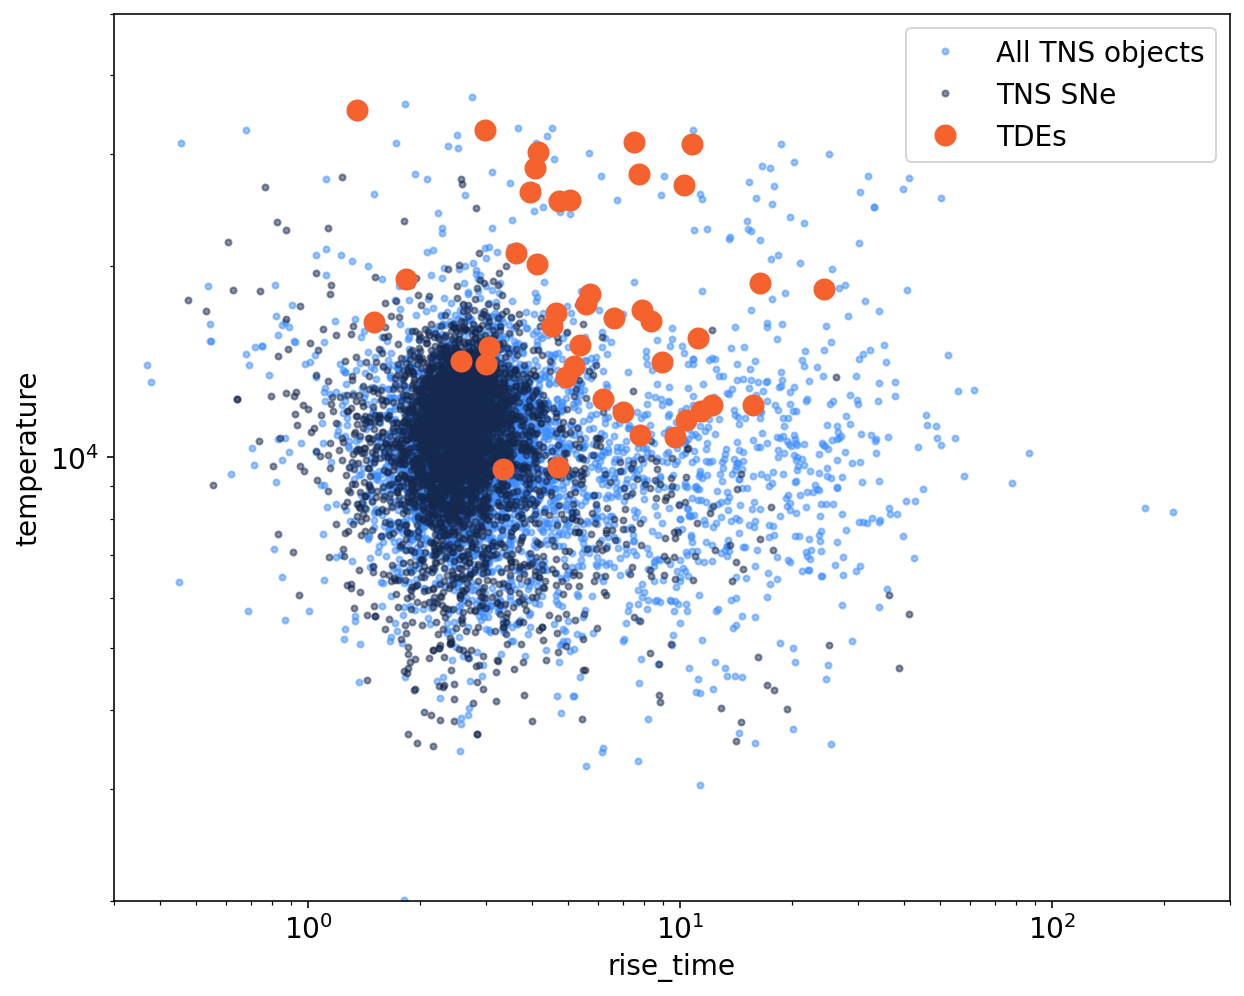

In [262]:
good_idx = features['r_chisq'] < 10
# good_idx &= np.isin(features['objectId'], features0['objId'])

good_idx &= features['num_hist_detections'] < 1 # No detections in 100 days prior to the window
# good_idx &= features['num_hist_negatives'] == 0 # No negatives there
# good_idx &= (features['num_hist_limits'] > 0) | (features['num_limits'] > 0) # Upper limits in either window or within 100 days prior to it

# good_idx &= features['num_prehist_detections'] <= 1 # No more than 1 detection prior to the window
good_idx &= features['num_prehist_negatives'] <= 1 # No negatives prior to the window

good_idx &= features['e_reference_time'] < 100

# good_idx &= features['rel_reference_time'] < 100
# good_idx &= features['rel_reference_time'] > -100
good_idx &= features['norm_rel_reference_time'] < 0 # 10
good_idx &= features['norm_rel_reference_time'] > -10
# good_idx &= features['rel_reference_time'] > -10*features['rise_time']

# good_idx &= features['snr_amplitude'] > 1.5
good_idx &= features['snr_rise_time'] > 1.5
good_idx &= features['snr_temperature'] > 1.5

good0_idx = good_idx.copy()
good_idx &= features['pcounter'] == 0 # Only last sets of features for every peak

# good_idx &= features['distnr'] < 1.5

# tns_idx = np.isin(features['objectId'], tns_types['objectId'].values.astype(str)) # Everything in TNS
tns_idx = np.isin(features['objectId'], tns_tdes + tns_nontdes) # Everything in TNS

tns_all_idx = np.isin(features['objectId'], tns_all) # all in TNS
tde_idx = np.isin(features['objectId'], tns_tdes + maybe_tdes + additional_tdes) # TDEs in TNS
sn_idx = np.array([_.startswith('SN') for _ in features['tns']]) # SNe in TNS

fleet_idx = np.isin(features['objectId'], fleet['objectId'])
ant_idx = np.isin(features['objectId'], ant_tdes)

print(np.sum(good_idx), 'good')
print(np.sum(good_idx & tns_idx), 'good TNS')
print(np.sum(good_idx & tde_idx), 'good TDEs')
print(np.sum(good_idx & sn_idx), 'good SNe')
print(np.sum(good_idx & fleet_idx), 'good FLEETs')
print(np.sum(good_idx & ant_idx), 'good ANTs')

# Plotting 
plt.figure(figsize=(10,8))

# plt.plot(features['rise_time'][good_idx & ~tde_idx & ~sn_idx], features['T'][good_idx & ~tde_idx & ~sn_idx], '.', alpha=0.2, label='All objects')
plt.plot(features['rise_time'][good_idx & tns_all_idx & ~tde_idx & ~sn_idx], features['temperature'][good_idx & tns_all_idx & ~tde_idx & ~sn_idx], '.', color=COLORS_ZTF[3], alpha=0.5, label='All TNS objects', rasterized=True)
plt.plot(features['rise_time'][good_idx & sn_idx], features['temperature'][good_idx & sn_idx], '.', color=COLORS_ZTF[1], alpha=0.5, label='TNS SNe', rasterized=True)
plt.plot(features['rise_time'][good_idx & tde_idx], features['temperature'][good_idx & tde_idx], 'o', color=COLORS_ZTF[2], ms=10, label='TDEs')
# plt.plot(features['rise_time'][good_idx & fleet_idx], features['T'][good_idx & fleet_idx], 'o', color='magenta', label='FLEETs')

plt.legend()
plt.xscale('log')
plt.yscale('log')
plt.xlabel('rise_time')
plt.ylabel('temperature')
# plt.grid(alpha=0.2)
plt.xlim(3e-1, 3e2)
plt.ylim(2e3, 5e4)
plt.savefig('/home/karpov/fink/tde/figures/fig_tns_rise_temp.pdf', bbox_inches='tight')

/tmp/ipykernel_14157/1376272138.py:53: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


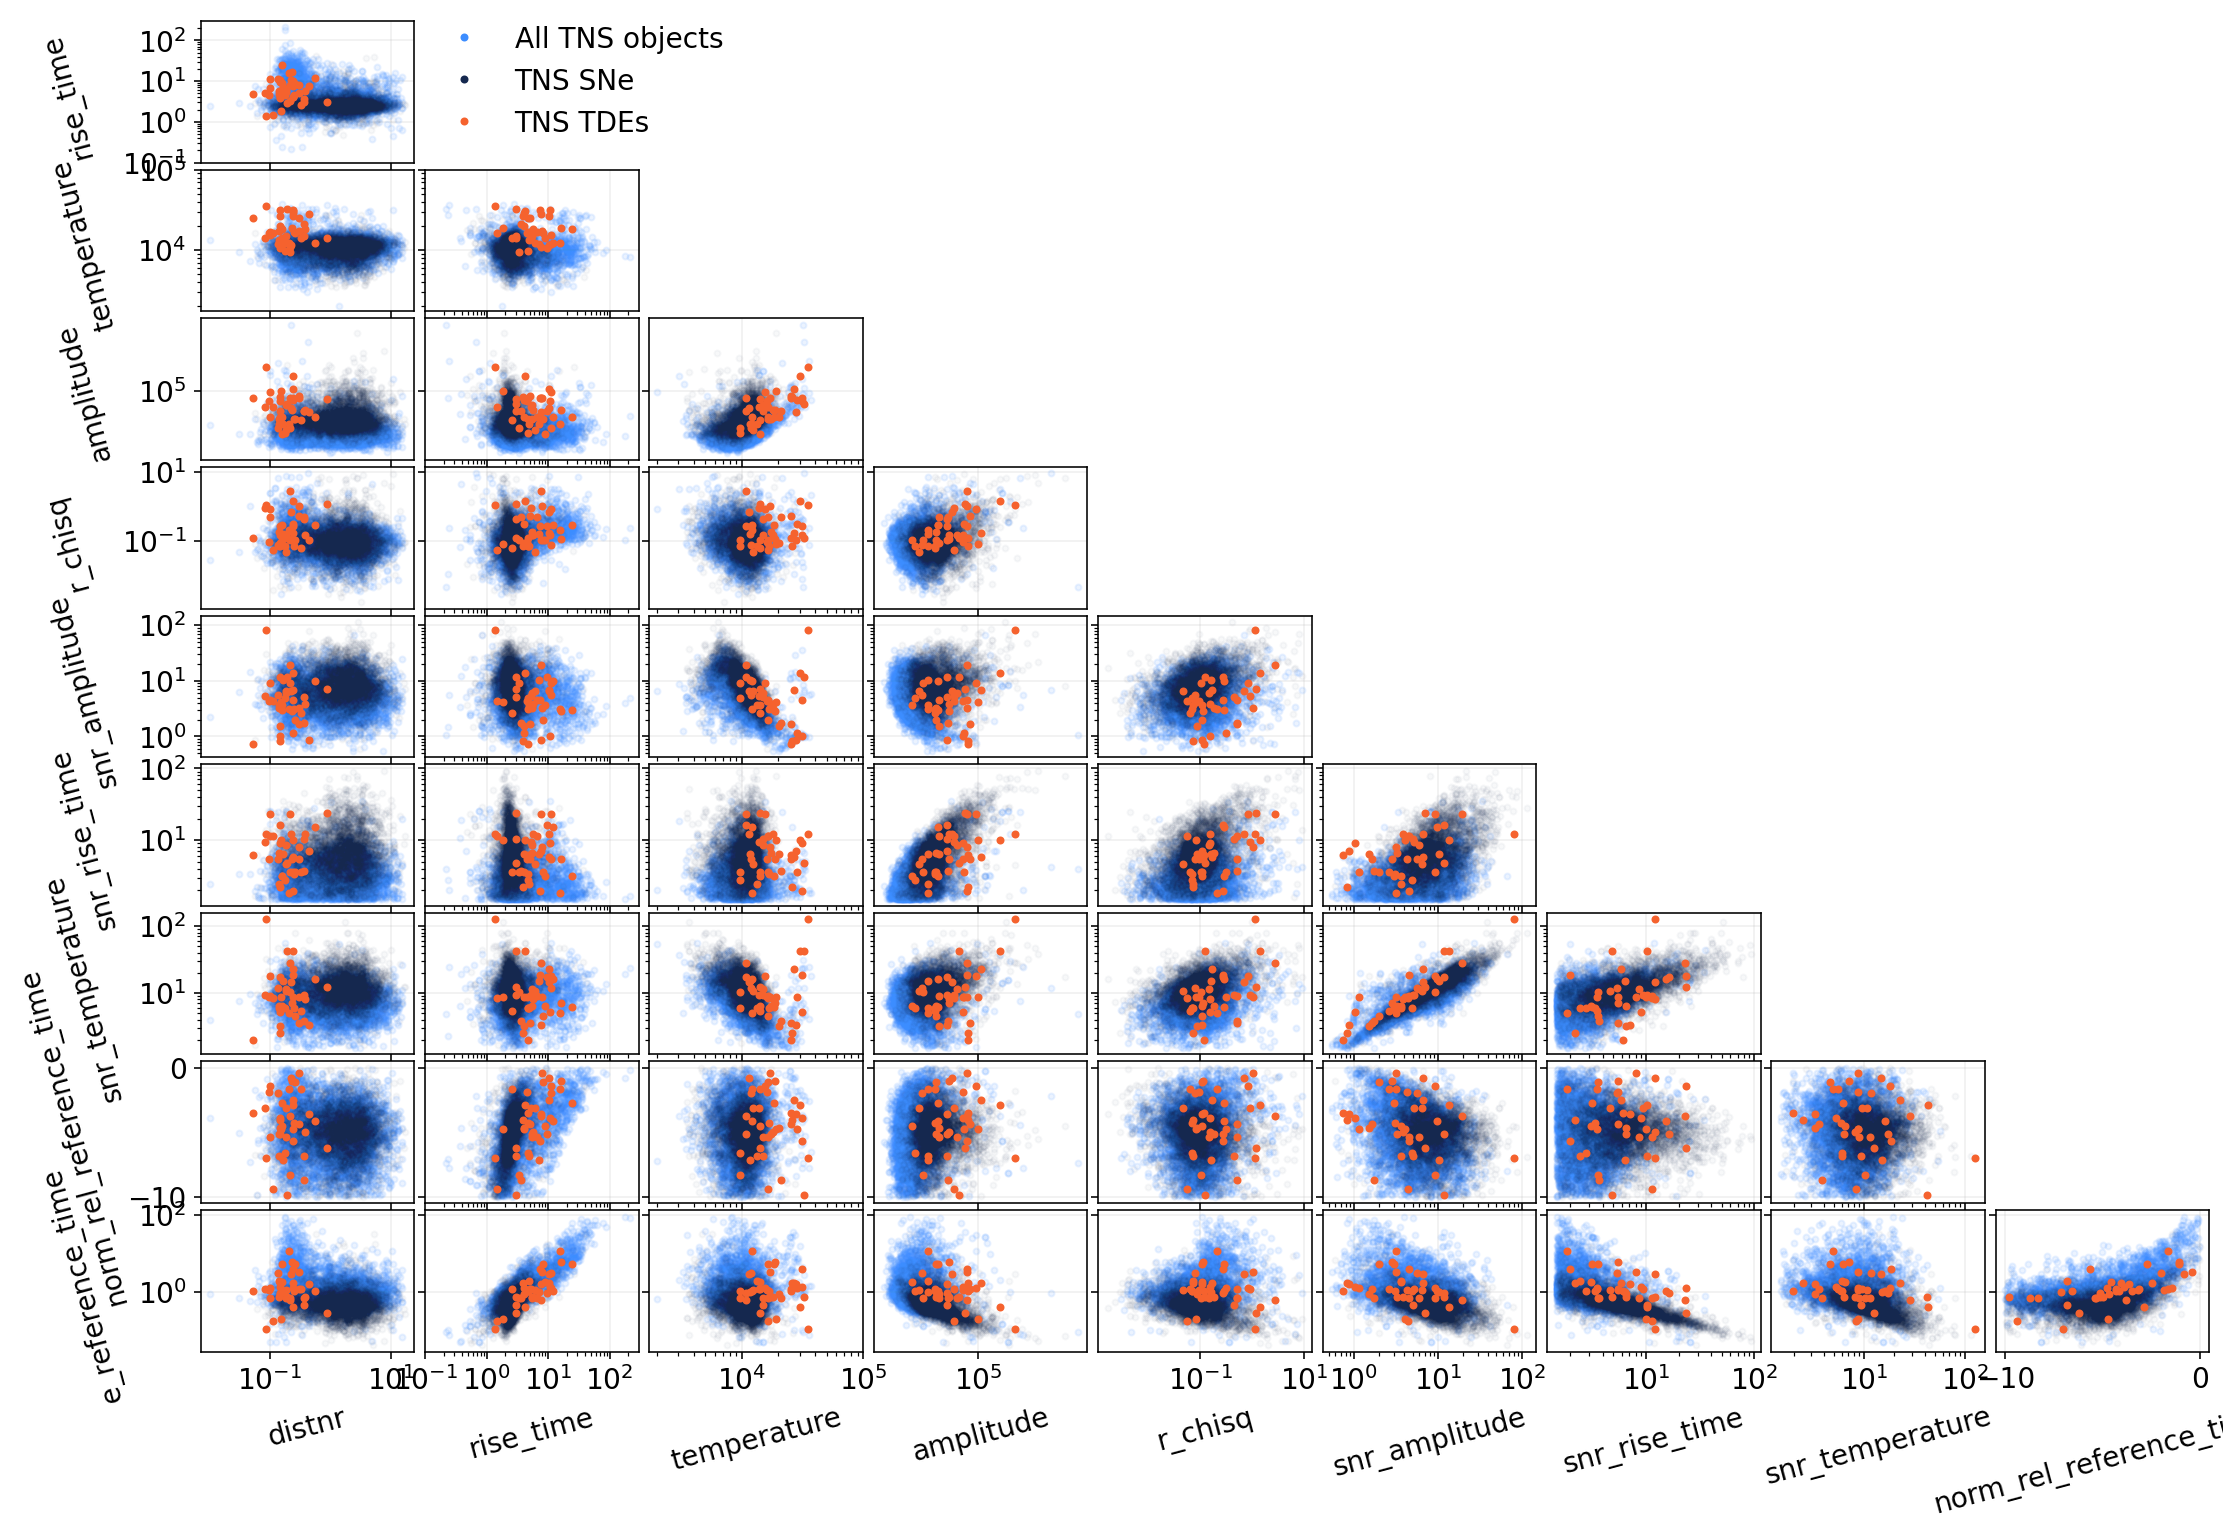

In [261]:
cols = ['distnr', 'rise_time', 'temperature', 'amplitude', 'r_chisq', 'snr_amplitude', 'snr_rise_time', 'snr_temperature', 'norm_rel_reference_time', 'e_reference_time']

Nx = Ny = len(cols) - 1

plt.figure(figsize=(18,12))
for iy in range(Ny):
    for ix in range(0, iy+1):
        col1,col2 = cols[ix], cols[iy+1]
    
        plt.subplot(Nx, Ny, ix + iy*Nx + 1)
        plt.grid(alpha=0.2)
        
        if ix == 0:
            plt.ylabel(col2, rotation=105, labelpad=20)
        if iy == Ny - 1:
            plt.xlabel(col1, rotation=15)

        # Main plotting
        plt.plot(features[col1][good_idx & tns_all_idx & ~tde_idx & ~sn_idx], features[col2][good_idx & tns_all_idx & ~tde_idx & ~sn_idx], '.', alpha=0.1, color=COLORS_ZTF[3], label='All TNS objects', rasterized=True)
        plt.plot(features[col1][good_idx & sn_idx], features[col2][good_idx & sn_idx], '.', alpha=0.03, color=COLORS_ZTF[1], label='TNS SNe', rasterized=True)
        
        plt.plot(features[col1][good_idx & tde_idx], features[col2][good_idx & tde_idx], '.', alpha=1, color=COLORS_ZTF[2], label='TNS TDEs')
        
        if col1 == 'rise_time':
            plt.xscale('log')
            plt.xlim(1e-1, )
        if col2 == 'rise_time':
            plt.yscale('log')
            plt.ylim(1e-1, )
            
        if col1 == 'temperature':
            plt.xscale('log')
            plt.xlim(None, 1e5)
        if col2 == 'temperature':
            plt.yscale('log')
            plt.ylim(None, 1e5)
            
        if col1.startswith('snr_') or col1 in ['e_reference_time', 'r_chisq', 'amplitude', 'distnr']:
            plt.xscale('log')
        if col2.startswith('snr_') or col2 in ['e_reference_time', 'r_chisq', 'amplitude', 'distnr']:
            plt.yscale('log')
            
        if ix > 0:
            plt.gca().set_yticklabels([])            
        if iy < Ny - 1:
            plt.gca().set_xticklabels([])
            
        if ix == 0 and iy == 0:
            legend = plt.legend(loc=(1.05, 0.1), frameon=False, )
        for _ in legend.legend_handles:
            _.set_alpha(1)

plt.tight_layout()
plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.savefig('/home/karpov/fink/tde/figures/fig_cornerplot_full.pdf', bbox_inches='tight')

# Classifier

In [223]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier 

import xgboost as xgb
from sklearn.model_selection import train_test_split, LeaveOneOut, cross_val_score, cross_validate, GridSearchCV, ParameterGrid, RandomizedSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [670]:
colnames_exclude = ['objectId', 'jd_min', 'jd_max', 'reference_time', 'type', 'tns_name', 'tns', 'counter', 'pcounter', 'raw']
colnames_exclude += [_ for _ in features.colnames if _.startswith('num_')]
colnames_exclude += ['distnr_g', 'distnr_r']
colnames_exclude += ['e_amplitude', 'e_rise_time', 'e_temperature']
colnames_exclude += ['r_chisq']
colnames_exclude += ['Ebv']
colnames_exclude += ['amplitude']
colnames_exclude += ['snr_amplitude']
colnames_exclude += ['snr_rise_time']
colnames_exclude += ['snr_temperature', 'norm_rel_reference_time']
colnames_exclude += ['rel_reference_time']
colnames_exclude += ['distnr']

colnames = [_ for _ in features.colnames if _ not in colnames_exclude]

# colnames = ['rise_time', 'T', 'distnr']
print('Columns:', " ".join(colnames))

idx = good_idx & tns_all_idx # Train on all labelled TNS objects
idx &= features['pcounter'] == 0 # Only train on latest pre-peak alerts
# idx &= features['num_prehist_detections'] == 0 # No detections prior to the window
# idx = good_idx & (sn_idx | tde_idx) 
X = features[colnames][idx].to_pandas()
labels = (tde_idx[idx] == True) #& (features['rise_time'][idx] > 2)
labels_fleet = (fleet_idx[idx] == True)

print(len(X), "rows for classification")
print(np.sum(labels), "TDEs")

Columns: e_reference_time rise_time temperature
8866 rows for classification
42 TDEs


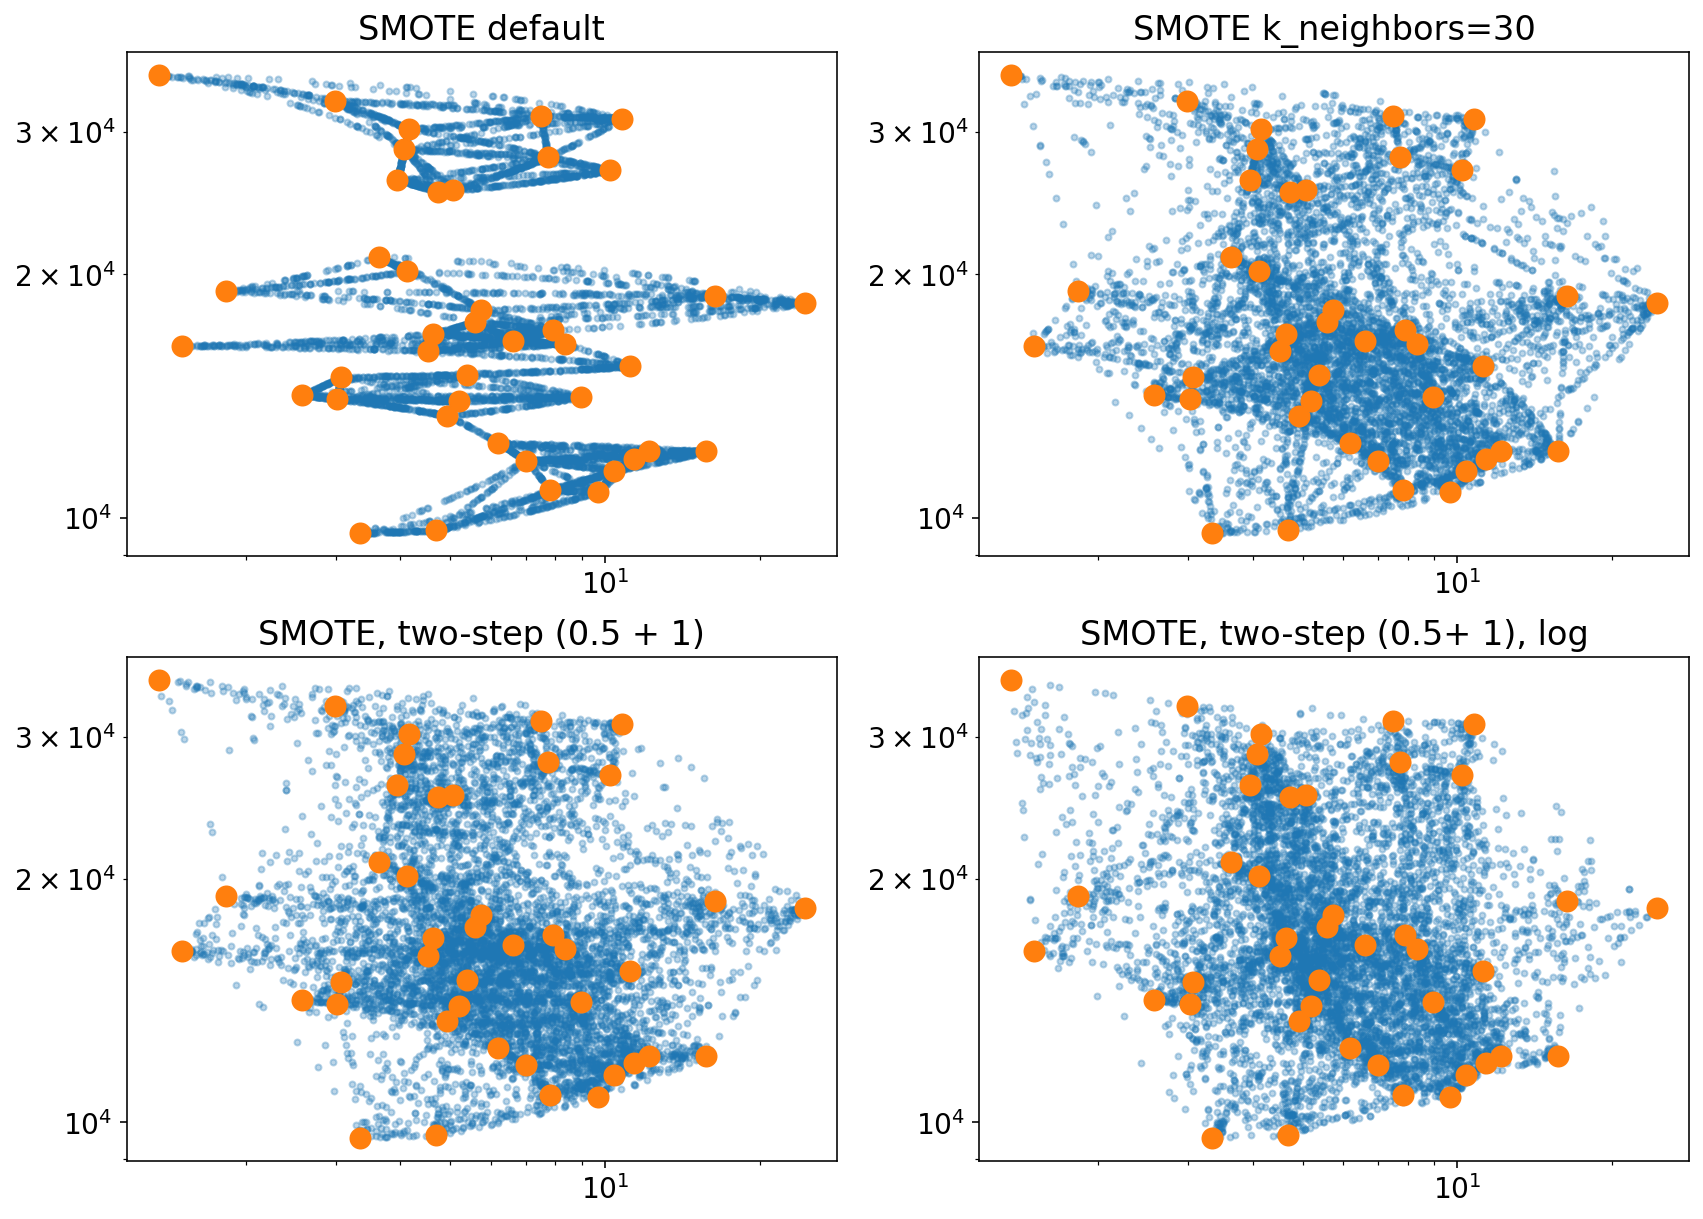

In [607]:
from imblearn.over_sampling import SMOTE, ADASYN, BorderlineSMOTE, KMeansSMOTE, SVMSMOTE
from imblearn.combine import SMOTEENN, SMOTETomek

smote0 = SMOTE(random_state=1)
smote = SMOTE(k_neighbors=30, random_state=1)
smote1 = SMOTE(k_neighbors=30, sampling_strategy=0.5, random_state=1)
smote2 = SMOTE(k_neighbors=300, random_state=1)

# plt.subplot(2,2,1)
# plt.plot(X['rise_time'][labels], X['temperature'][labels], 'o', color='C1', alpha=1, ms=10)
# plt.title('Original')
# plt.xscale('log')
# plt.yscale('log')

plt.subplot(2,2,1)
X1, labels1 = smote0.fit_resample(X, labels)
plt.plot(X1['rise_time'][labels1], X1['temperature'][labels1], '.', alpha=0.3)
plt.plot(X['rise_time'][labels], X['temperature'][labels], 'o', color='C1', alpha=1, ms=10)
plt.title('SMOTE default')
plt.xscale('log')
plt.yscale('log')

plt.subplot(2,2,2)
X1, labels1 = smote.fit_resample(X, labels)
plt.plot(X1['rise_time'][labels1], X1['temperature'][labels1], '.', alpha=0.3)
plt.plot(X['rise_time'][labels], X['temperature'][labels], 'o', color='C1', alpha=1, ms=10)
plt.title('SMOTE k_neighbors=30')
plt.xscale('log')
plt.yscale('log')

plt.subplot(2,2,3)
X1, labels1 = smote1.fit_resample(X, labels)
X1, labels1 = smote2.fit_resample(X1, labels1)
plt.plot(X1['rise_time'][labels1], X1['temperature'][labels1], '.', alpha=0.3)
plt.plot(X['rise_time'][labels], X['temperature'][labels], 'o', color='C1', alpha=1, ms=10)
plt.title('SMOTE, two-step (0.5 + 1)')
plt.xscale('log')
plt.yscale('log')

plt.subplot(2,2,4)
X1, labels1 = smote1.fit_resample(np.log10(X), labels)
X1, labels1 = smote2.fit_resample(X1, labels1)
X1 = 10**(X1)

plt.plot(X1['rise_time'][labels1], X1['temperature'][labels1], '.', alpha=0.3)
plt.plot(X['rise_time'][labels], X['temperature'][labels], 'o', color='C1', alpha=1, ms=10)
plt.title('SMOTE, two-step (0.5+ 1), log')
plt.xscale('log')
plt.yscale('log')

# X1, labels1 = smote1.fit_resample(np.log10(X), labels)
# # X1, labels1 = smote1.fit_resample(X, labels)
# X1, labels1 = smote2.fit_resample(X1, labels1)
# X1 = 10**(X1)




# plt.plot(X1['rise_time'][labels1], X1['temperature'][labels1], '.', alpha=1)

# plt.plot(X['rise_time'][labels], X['temperature'][labels], 'o', alpha=1, ms=10)

# plt.xscale('log')
# plt.yscale('log')

In [522]:
from sklearn import metrics
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV,HalvingRandomSearchCV

import warnings
warnings.simplefilter('ignore', UserWarning)

In [671]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

to_log10 = FunctionTransformer(np.log10, lambda _: 10**_)
from_log10 = FunctionTransformer(lambda _: 10**_, np.log10)

# Two-step SMOTE
smote1 = SMOTE(k_neighbors=30, sampling_strategy=0.5, random_state=1)
smote2 = SMOTE(k_neighbors=300, random_state=1)

if 'distnr' in colnames:
    # With distnr
    clf = xgb.XGBClassifier(n_estimators=100, scale_pos_weight=pos_weight, max_depth=3, subsample=0.2, learning_rate=0.02, reg_lambda=5, reg_alpha=10, min_child_weight=10, colsample_bytree=0.7, random_state=1)
else:
    # Without distnr
    clf = xgb.XGBClassifier(n_estimators=100, scale_pos_weight=pos_weight, max_depth=3, subsample=0.1, learning_rate=0.02, reg_lambda=5, reg_alpha=10, min_child_weight=10, colsample_bytree=1.0, random_state=1)
    
pipeline = Pipeline(steps=[
    ('to_log10', to_log10),
    ('smote1', smote1), 
    ('smote2', smote2), 
    ('from_log10', from_log10),
    ('model', clf)
])

pipeline.fit(X, labels)

tde_score = clf.predict(features[colnames].to_pandas())
print(np.sum(tde_score == 1), 'predicted TDEs')
print(np.sum(tde_score[good_idx] == 1), 'predicted good TDEs')
print(np.sum(tde_score[good_idx & ~tns_idx] == 1), 'predicted good non-TNS TDEs')

print(np.sum(tde_score[good_idx & fleet_idx] == 1), 'predicted good FLEETs')
print(np.sum(tde_score[good_idx & ant_idx] == 1), 'predicted good ANTs')




88915 predicted TDEs
1653 predicted good TDEs
1413 predicted good non-TNS TDEs
5 predicted good FLEETs
2 predicted good ANTs


In [672]:
%%time

param_grid = {
    'max_depth': [3],#, 6, 7], 
    'n_estimators': [50, 100, 200],#, 300, 400], 
    'scale_pos_weight': [1], # [200, 250, 300, 400, 500, 600],
    'subsample': [0.2, 0.5, 0.8, 1.0],#np.arange(0.1, 1.0, 0.1), # [0.1, 0.2, 0.5, 0.8], 
    'learning_rate': np.arange(0.01, 0.1, 0.01), # [0.01, 0.05, 0.1], 
    'min_child_weight': [1, 5],#, 10, 50, 100], # np.logspace(0, 3, 10),#[10], 
    'colsample_bytree': [0.5, 0.7, 0.9, 1.0], #np.arange(0.1, 1.0, 0.1), #[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    'reg_lambda': [1, 5, 10], # [0, 0.1, 1, 5, 10], 
    'reg_alpha': [1, 10, 50], #[1, 5, 10, 50, 100], 
}

gs = RandomizedSearchCV(
    pipeline, 
#     param_grid, 
    {'model__'+_:__ for _,__ in param_grid.items()},
    cv=5, 
    n_iter=100, 
    scoring=metrics.make_scorer(metrics.fbeta_score, beta=2), 
    verbose=1,
    random_state=1,
)

gs.fit(X, labels)

print(f"best score: {gs.best_score_}")

print("best params:\n")
for _,__ in gs.best_params_.items():
    print(f"{_[7:]:20s} = {__}")
print("\n")


Fitting 5 folds for each of 100 candidates, totalling 500 fits
best score: 0.22440502605129029
best params:

subsample            = 0.8
scale_pos_weight     = 1
reg_lambda           = 1
reg_alpha            = 1
n_estimators         = 200
min_child_weight     = 5
max_depth            = 3
learning_rate        = 0.060000000000000005
colsample_bytree     = 1.0


CPU times: user 17min 31s, sys: 2.01 s, total: 17min 33s
Wall time: 2min 15s


In [673]:
# Store the model
# from pickle import dump
# with open("early_tde_xgboost.pickle", "wb") as f:
#     dump(clf, f, protocol=5)

# Use XGBoost' method for saving its model
if 'distnr' in colnames:
    clf.save_model('early_tde_xgboost.final.dereddened.ubj')
else:
    clf.save_model('early_tde_xgboost.final.dereddened.nodistnr.ubj')

In [674]:
clf = gs.best_estimator_['model']
tde_score = clf.predict(features[colnames].to_pandas())

print(np.sum(tde_score == 1), 'predicted TDEs')
print(np.sum(tde_score[good_idx] == 1), 'predicted good TDEs')
print(np.sum(tde_score[good_idx & ~tns_idx] == 1), 'predicted good non-TNS TDEs')

print(np.sum(tde_score[good_idx & fleet_idx] == 1), '/', np.sum(good_idx & fleet_idx), 'predicted good FLEETs')
print(np.sum(tde_score[good_idx & ant_idx] == 1), '/', np.sum(good_idx & ant_idx), 'predicted good ANTs')

15126 predicted TDEs
876 predicted good TDEs
674 predicted good non-TNS TDEs
2 / 8 predicted good FLEETs
1 / 2 predicted good ANTs


In [675]:
scores = {
    'f1': 'f1', 
    'f05': metrics.make_scorer(metrics.fbeta_score, beta=0.5),
    'f2': metrics.make_scorer(metrics.fbeta_score, beta=2),
    'precision': 'precision', 
    'recall': 'recall'
}
# cvs = cross_validate(clf, X, labels, scoring=scores, cv=10)
cvs = cross_validate(pipeline, X, labels, scoring=scores, cv=5)
for _ in scores:
    print(f"{_} = {np.mean(cvs['test_'+_]):.2f} +/- {np.std(cvs['test_'+_]):.2f}")

f1 = 0.09 +/- 0.02
f05 = 0.06 +/- 0.01
f2 = 0.20 +/- 0.04
precision = 0.05 +/- 0.01
recall = 0.83 +/- 0.15


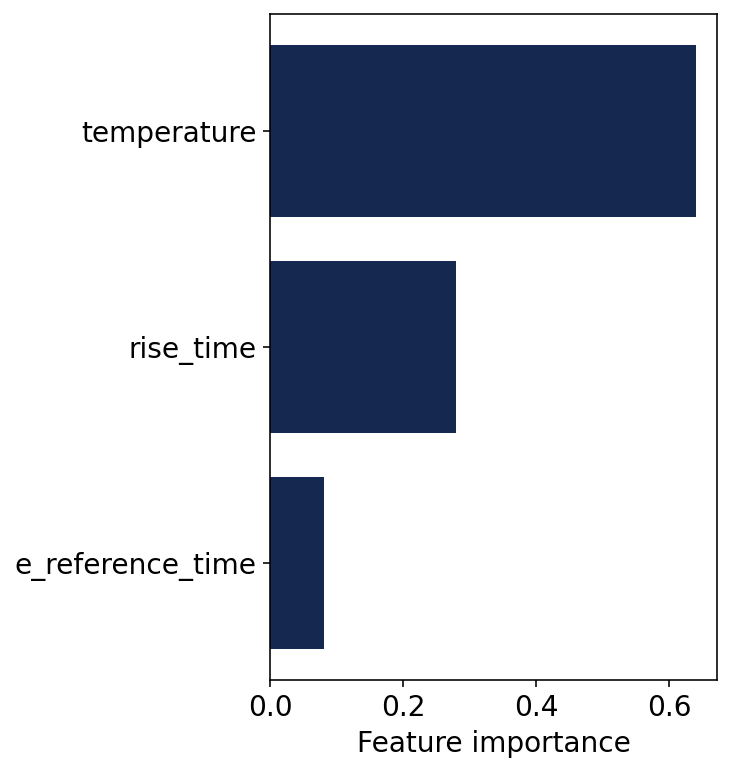

In [676]:
# Feature importance
aidx = np.argsort(clf.feature_importances_)
plt.figure(figsize=(4,6))
plt.barh(clf.feature_names_in_[aidx], clf.feature_importances_[aidx], color=COLORS_ZTF[1])
plt.xlabel('Feature importance')
# plt.grid(alpha=0.2)
if 'distnr' in colnames:
    plt.savefig('/home/karpov/fink/tde/figures/fig_feature_importances.pdf', bbox_inches='tight')
else:
    plt.savefig('/home/karpov/fink/tde/figures/fig_feature_importances.nodistnr.pdf', bbox_inches='tight')

932 splits in LOO


  0%|          | 0/932 [00:00<?, ?it/s]

Leave-One-Out cross-validation on TDEs
F1 score is 0.13
F05 score is 0.08
F2 score is 0.25
precision 0.07
recall 0.74


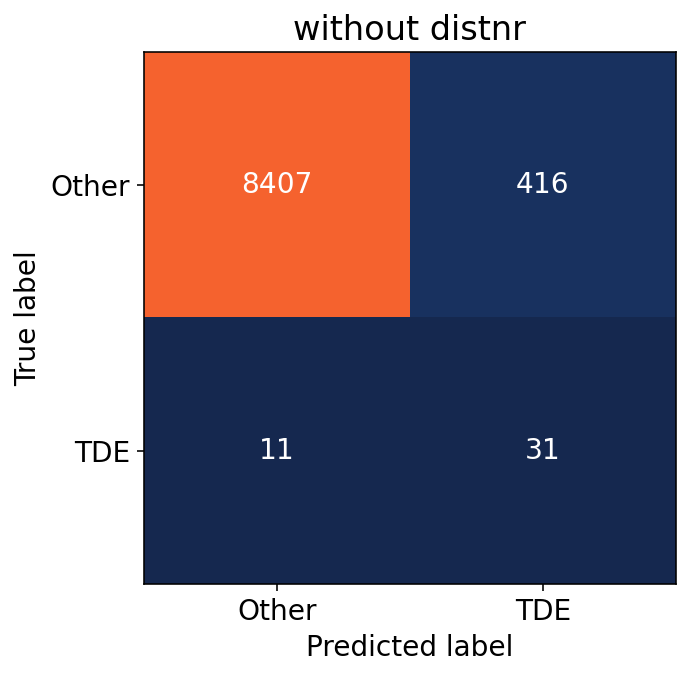

In [677]:
# LOO cross-validation

loo = LeaveOneOut()
splits = []
for train_idx,test_idx in loo.split(X, labels):
    if np.sum(labels[test_idx]) > 0 or np.random.uniform() > 0.9:
        splits.append((train_idx, test_idx))
print(len(splits), 'splits in LOO')

from sklearn.base import clone
clf1 = clone(clf)

scale_weight = np.sum(~labels) / (len(splits) - np.sum(labels))
cms = []
for train_idx,test_idx in tqdm(splits):
#     clf.fit(X.iloc[train_idx], labels[train_idx])
    X1, labels1 = smote1.fit_resample(np.log10(X).iloc[train_idx], labels[train_idx])
    X1, labels1 = smote2.fit_resample(X1, labels1)
    X1 = 10**(X1)
    clf1.fit(X1, labels1)

    cm = confusion_matrix(
        labels[test_idx], clf1.predict(X.iloc[test_idx]), labels=[False, True], 
        sample_weight=np.where(labels[test_idx], 1, scale_weight)
    )
    cms.append(cm)
        
cm = np.sum(cms, axis=0)
precision = cm[1,1] / (cm[1,1] + cm[0,1])
recall = cm[1,1] / (cm[1,1] + cm[1,0])

f1 = 2 * precision * recall / (precision + recall)
f05 = (1 + 0.5**2) * precision * recall / (0.5**2 * precision + recall)
f2 = (1 + 2**2) * precision * recall / (2**2 * precision + recall)
    
print('Leave-One-Out cross-validation on TDEs')
print(f"F1 score is {f1:.2f}")
print(f"F05 score is {f05:.2f}")
print(f"F2 score is {f2:.2f}")
print(f"precision {precision:.2f}")
print(f"recall {recall:.2f}")

plt.figure(figsize=(5,5))
# plt.figure(figsize=(12,6))
# plt.subplot(1,2,1)
ConfusionMatrixDisplay(confusion_matrix=cm.astype(int), display_labels=['Other', 'TDE']).plot(colorbar=False, ax=plt.gca(), cmap=fink_colormap, text_kw={'color': 'white'})
# plt.subplot(1,2,2)
# ConfusionMatrixDisplay(confusion_matrix=(cm.T/(cm[:,0] + cm[:,1])).T, display_labels=['Other', 'TDE']).plot(colorbar=False, ax=plt.gca())
plt.tight_layout()

if 'distnr' in colnames:
    plt.title('with distnr')
    plt.savefig('/home/karpov/fink/tde/figures/fig_confusion.pdf', bbox_inches='tight')
else:
    plt.title('without distnr')
    plt.savefig('/home/karpov/fink/tde/figures/fig_confusion.nodistnr.pdf', bbox_inches='tight')


## Cornerplots

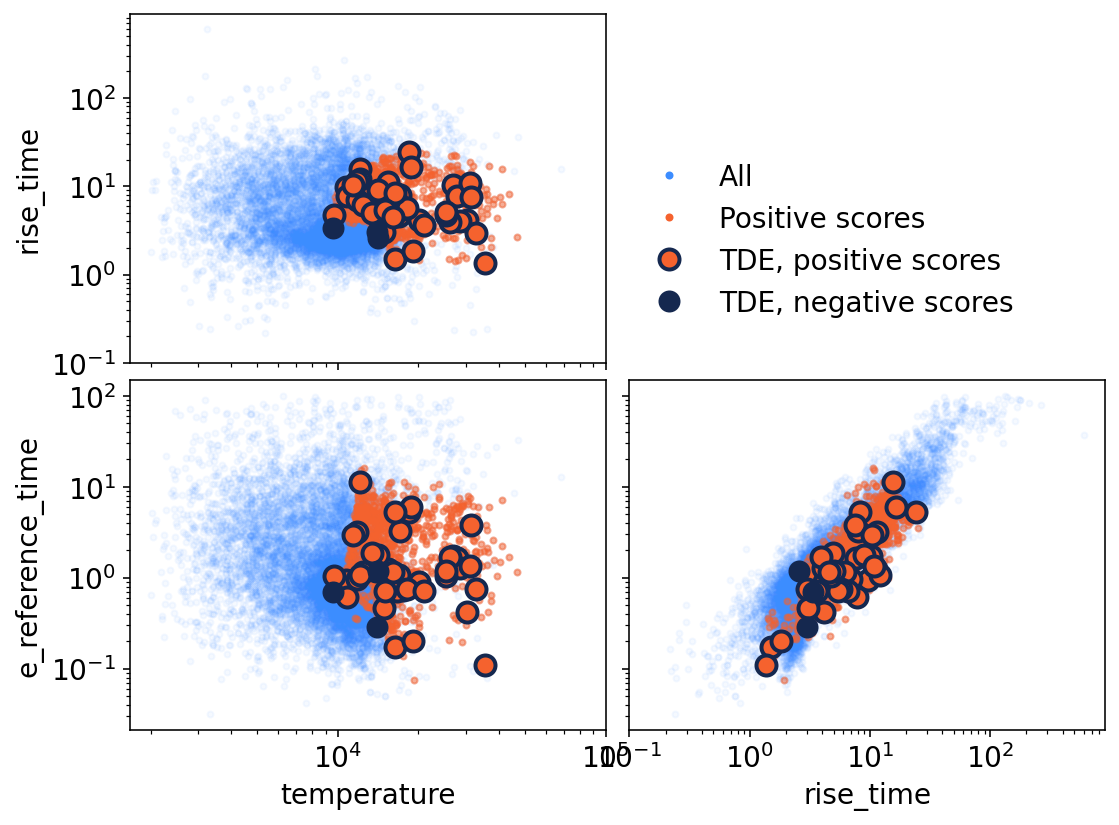

In [678]:
cols = clf.feature_names_in_[np.argsort(clf.feature_importances_)[::-1]]#[:6]
# cols = ['rise_time', 'T', 'norm_rel_reference_time', 'snr_rise_time', 'snr_amplitude', 'r_chisq', 'distnr']
# cols = colnames

Nx = Ny = len(cols) - 1

plt.figure(figsize=(8,6))
# plt.figure(figsize=(16,12))
for iy in range(Ny):
    for ix in range(0, iy+1):
        col1,col2 = cols[ix], cols[iy+1]
    
        plt.subplot(Nx, Ny, ix + iy*Nx + 1)
        # plt.grid(alpha=0.2)
        
        if ix == 0:
            plt.ylabel(col2)
        if iy == Ny - 1:
            plt.xlabel(col1)

        # Main plotting
        plt.plot(features[col1][good_idx], features[col2][good_idx], '.', alpha=0.05, color=COLORS_ZTF[3], rasterized=True, label='All')
#         plt.plot(features[col1][good_idx & sn_idx], features[col2][good_idx & sn_idx], '.', alpha=0.1, color='C0')
        plt.plot(features[col1][good_idx & (tde_score == 1)], features[col2][good_idx & (tde_score == 1)], '.', alpha=0.5, color=COLORS_ZTF[2], label='Positive scores', rasterized=True)
        
        plt.plot(features[col1][good_idx & tde_idx & (tde_score == 1)], features[col2][good_idx & tde_idx & (tde_score == 1)], 'o', alpha=1, color=COLORS_ZTF[2], mec=COLORS_ZTF[1], ms=10, mew=2, label='TDE, positive scores')
        plt.plot(features[col1][good_idx & tde_idx & (tde_score == 0)], features[col2][good_idx & tde_idx & (tde_score == 0)], 'o', alpha=1, color=COLORS_ZTF[1], ms=10, label='TDE, negative scores')

#         plt.plot(features[col1][good_idx & fleet_idx & (tde_score == 1)], features[col2][good_idx & fleet_idx & (tde_score == 1)], 'o', alpha=1, color=COLORS_ZTF[2], mec=COLORS_ZTF[1], ms=10, mew=2, label='TDE, positive scores')
#         plt.plot(features[col1][good_idx & fleet_idx & (tde_score == 0)], features[col2][good_idx & fleet_idx & (tde_score == 0)], 'o', alpha=1, color=COLORS_ZTF[1], ms=10, label='TDE, negative scores')

        if col1 == 'rise_time':
            plt.xscale('log')
            plt.xlim(1e-1, )
        if col2 == 'rise_time':
            plt.yscale('log')
            plt.ylim(1e-1, )
            
        if col1 == 'temperature':
            plt.xscale('log')
            plt.xlim(None, 1e5)
        if col2 == 'temperature':
            plt.yscale('log')
            plt.ylim(None, 1e5)
            
        if col1.startswith('snr_') or col1 in ['e_reference_time', 'r_chisq', 'amplitude', 'distnr']:
            plt.xscale('log')
        if col2.startswith('snr_') or col2 in ['e_reference_time', 'r_chisq', 'amplitude', 'distnr']:
            plt.yscale('log')
            
        if ix > 0:
            plt.gca().set_yticklabels([])
        if iy < Ny - 1:
            plt.gca().set_xticklabels([])
            
        if ix == 0 and iy == 0:
            legend = plt.legend(loc=(1.05, 0.1), frameon=False, )
            for _ in legend.legend_handles:
                _.set_alpha(1)

plt.tight_layout()
plt.subplots_adjust(wspace=0.05, hspace=0.05)  

if 'distnr' in colnames:
    plt.savefig('/home/karpov/fink/tde/figures/fig_cornerplot.pdf', bbox_inches='tight')
else:
    plt.savefig('/home/karpov/fink/tde/figures/fig_cornerplot.nodistnr.pdf', bbox_inches='tight')

Text(0.5, 1.0, 'Trained on the whole dataset')

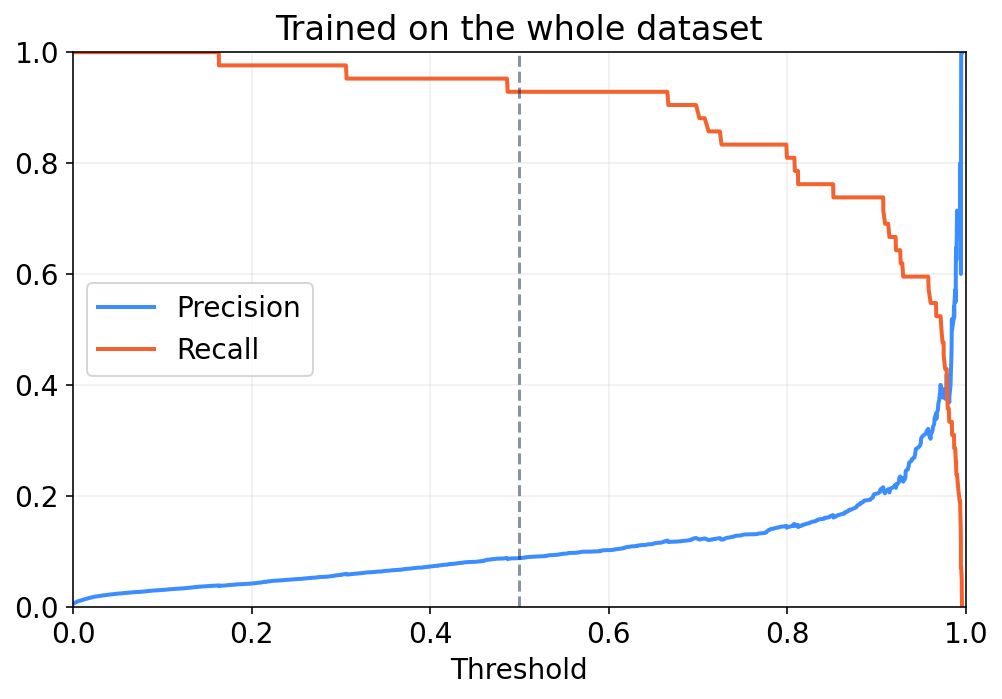

In [708]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve

plt.figure(figsize=(8,5))
# PrecisionRecallDisplay.from_estimator(clf, X, labels)
score = clf.predict_proba(X)
vp,vr,vt = precision_recall_curve(labels, score[:,1])
vt = np.insert(vt, 0, 0.0)
plt.plot(vt, vp, label='Precision', color=COLORS_ZTF[3], lw=2)
plt.plot(vt, vr, label='Recall', color=COLORS_ZTF[2], lw=2)

plt.axvline(0.5, ls='--', color=COLORS_ZTF[1], alpha=0.5)

plt.grid(alpha=0.2)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel('Threshold')
plt.legend(loc='center left')
plt.title('Trained on the whole dataset')

## Plotting of candidates

In [ ]:
# cand_idx = good_idx & ~tns_all_idx & (tde_score == 1) # Good non-TNS candidates
cand_idx = good_idx & tns_all_idx & (tde_score == 1) # Good TNS candidates
cand_idx &= ~tde_idx
cand_idx &= ~sn_idx
# cand_idx &= features['rise_time'] > 10
# cand_idx &= features['num_prehist_detections'] <= 1 # Exclude everything with history prior to 100 days
# cand_idx &= features['num_prehist_detections'] <= 1
# cand_idx &= features['num_prehist_negatives'] <= 1
# cand_idx = tde_idx & ~good_idx
# cand_idx &= ~tde_idx & good_idx & (features['rise_time'] < 2)
cand_idx &= features['pcounter'] == 0
# cand_idx &= features['distnr'] > 1

# cand_idx &= features['T'] < 5000

# cand_idx &= features['norm_rel_reference_time'] > 0

# cand_idx = good_idx & fleet_idx
# cand_idx = np.isin(features['objectId'], ['ZTF20abrbeie', 'ZTF19aamrjar', 'ZTF20abodaps', 'ZTF18aczpgwm', 'ZTF21abxowzx', 'ZTF19aailpwl', 'ZTF20abgxlut', 'ZTF22aadesap', 'ZTF20acvfraq', 'ZTF19aatubsj', 'ZTF20aanxcpf']) # ANTs
# cand_idx &= np.isin(features['objectId'], ['ZTF18abvylfa', 'ZTF18abilvuu'])
# cand_idx &= np.isin(features['objectId'], ['ZTF24aamfius'])

# cand_idx = np.isin(features['objectId'], fleet['objectId'])
# cand_idx &= features['pcounter'] == 0
# cand_idx &= np.isin(features['objectId'], ['ZTF20abrbeie', 'ZTF19aamrjar', 'ZTF20abodaps', 'ZTF18aczpgwm', 'ZTF21abxowzx', 'ZTF19aailpwl', 'ZTF20abgxlut', 'ZTF22aadesap', 'ZTF20acvfraq', 'ZTF19aatubsj', 'ZTF20aanxcpf'])

# cand_idx &= features['jd_max'] > 2460000 # More recent ones

# cand_idx &= features['objectId']=='ZTF19abuwgfg'

print(np.sum(cand_idx), 'candidates')

for i,cand in enumerate(features[cand_idx]):
    print(cand['objectId'], good_idx[cand_idx][i], tde_score[cand_idx][i])
#     display(cand)
    full = get_lc(data[data['objectId'] == cand['objectId']].iloc[0])
    sub = full[(full['i:jd'] >= cand['jd_min']) & (full['i:jd'] <= cand['jd_max'])]
    sub = cleanup_limits(sub)
        
    ra,dec = np.mean(data[data['objectId']==cand['objectId']][['i:ra', 'i:dec']], axis=0)
    
    plt.figure(figsize=(14,10))
    plt.subplot(2, 1, 1)
    plot_lc(full, show_limits=False, show_zero=True)
    plt.axvline(cand['jd_min']-2400000.5, ls='--', color='black', alpha=0.5, lw=2)
    plt.axvline(cand['jd_max']-2400000.5, ls='--', color='black', alpha=0.5, lw=2)
    
#     plt.axvspan(cand['jd_min']-2400000.5-100, cand['jd_min']-2400000.5, color='gray', hatch='//', fc='white', lw=0.5, alpha=0.5)
    plt.title(cand['objectId'] + '  :  ' + cand['type'] + '  :  ' + get_tns_info(ra=ra, dec=dec))
    plt.margins(0.02, 0.05)

    plt.legend(loc='upper left')

    plt.subplot(2, 1, 2)
    plot_features(
        sub, cand['raw'], show_limits=True, show_zero=True, prior=100, 
        extra=[
            '', 
            f"distnr = {cand['distnr']:.2f}", 
            f"rel_reference_time = {cand['rel_reference_time']:.1f}",
            f"norm_rel_reference_time = {cand['norm_rel_reference_time']:.1f}",
        ]
    )
    
    plt.margins(0.02, 0.05)
    
    plt.show()
    
    if i > 100:
        break
    
#     break

# Misc plots

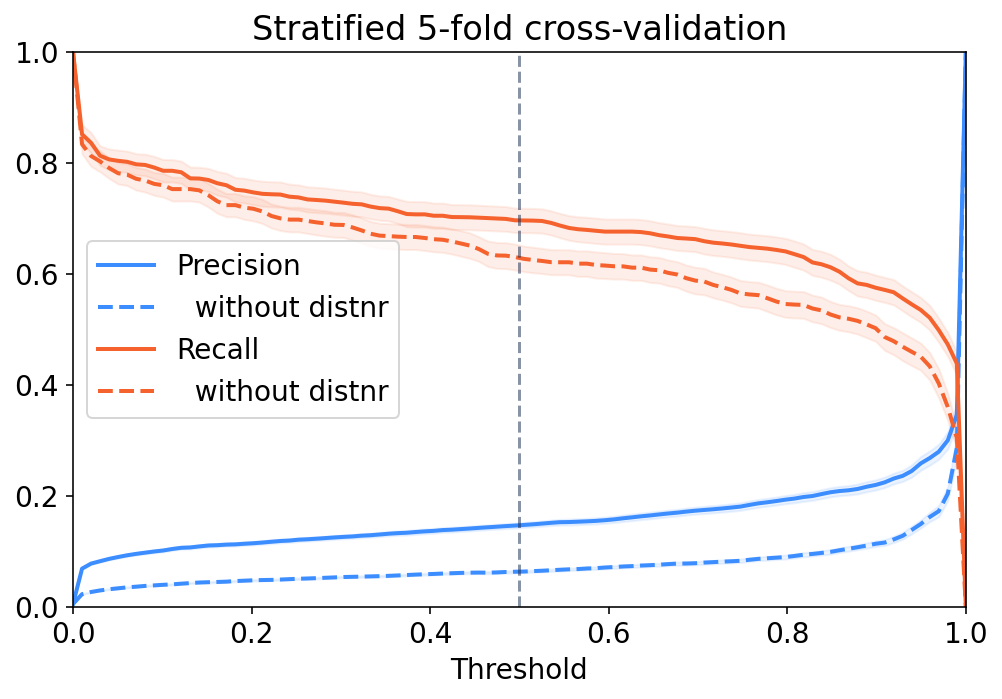

In [762]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve
from sklearn.model_selection import StratifiedKFold

from sklearn.base import clone
# clf1 = clone(clf)

clf1 = xgb.XGBClassifier()
clf1.load_model('early_tde_xgboost.final.dereddened.ubj')
clf1_nodistnr = xgb.XGBClassifier()
clf1_nodistnr.load_model('early_tde_xgboost.final.dereddened.nodistnr.ubj')

idx = good_idx & tns_all_idx # Train on all labelled TNS objects
idx &= features['pcounter'] == 0 # Only train on latest pre-peak alerts
XX = features[list(clf1.feature_names_in_)][idx].to_pandas()
XX_nodistnr = features[list(clf1_nodistnr.feature_names_in_)][idx].to_pandas()
llabels = (tde_idx[idx] == True) #& (features['rise_time'][idx] > 2)

vt = np.linspace(0, 1, 100)
vp,vr = [],[]
vp_nodistnr,vr_nodistnr = [],[]

skf = StratifiedKFold(n_splits=5, shuffle=True)
for iter in range(10):
    for train_idx,test_idx in skf.split(X, labels):
        X1, labels1 = smote1.fit_resample(np.log10(XX).iloc[train_idx], llabels[train_idx])
        X1, labels1 = smote2.fit_resample(X1, labels1)
        X1 = 10**(X1)
        clf1.fit(X1, labels1)

        score = clf1.predict_proba(XX.iloc[test_idx])
        vp1,vr1,vt1 = precision_recall_curve(labels[test_idx], score[:,1])
        vt1 = np.insert(vt1, 0, 0.0)

        aidx = np.argsort(vt1)
        vp.append(np.interp(vt, vt1[aidx], vp1[aidx]))
        vr.append(np.interp(vt, vt1[aidx], vr1[aidx]))

        X1, labels1 = smote1.fit_resample(np.log10(XX_nodistnr).iloc[train_idx], llabels[train_idx])
        X1, labels1 = smote2.fit_resample(X1, labels1)
        X1 = 10**(X1)
        clf1_nodistnr.fit(X1, labels1)

        score = clf1_nodistnr.predict_proba(XX_nodistnr.iloc[test_idx])
        vp1,vr1,vt1 = precision_recall_curve(labels[test_idx], score[:,1])
        vt1 = np.insert(vt1, 0, 0.0)

        aidx = np.argsort(vt1)
        vp_nodistnr.append(np.interp(vt, vt1[aidx], vp1[aidx]))
        vr_nodistnr.append(np.interp(vt, vt1[aidx], vr1[aidx]))

    
#     break
    
vpm = np.mean(vp, axis=0)
vps = np.std(vp, axis=0)/np.sqrt(len(vp))
vrm = np.mean(vr, axis=0)
vrs = np.std(vr, axis=0)/np.sqrt(len(vr))

vpm_nodistnr = np.mean(vp_nodistnr, axis=0)
vps_nodistnr = np.std(vp_nodistnr, axis=0)/np.sqrt(len(vp_nodistnr))
vrm_nodistnr = np.mean(vr_nodistnr, axis=0)
vrs_nodistnr = np.std(vr_nodistnr, axis=0)/np.sqrt(len(vr_nodistnr))

plt.figure(figsize=(8,5))

plt.plot(vt, vpm, label='Precision', color=COLORS_ZTF[3], lw=2)
plt.plot(vt, vpm_nodistnr, label='  without distnr', color=COLORS_ZTF[3], ls='--', lw=2)

plt.plot(vt, vrm, label='Recall', color=COLORS_ZTF[2], lw=2)
plt.plot(vt, vrm_nodistnr, label='  without distnr', color=COLORS_ZTF[2], ls='--', lw=2)

plt.fill_between(vt, vpm-vps, vpm+vps, color=COLORS_ZTF[3], alpha=0.1)
plt.fill_between(vt, vrm-vrs, vrm+vrs, color=COLORS_ZTF[2], alpha=0.1)

plt.fill_between(vt, vpm_nodistnr-vps_nodistnr, vpm_nodistnr+vps_nodistnr, color=COLORS_ZTF[3], alpha=0.1)
plt.fill_between(vt, vrm_nodistnr-vrs_nodistnr, vrm_nodistnr+vrs_nodistnr, color=COLORS_ZTF[2], alpha=0.1)

plt.axvline(0.5, ls='--', color=COLORS_ZTF[1], alpha=0.5)

# plt.grid(alpha=0.2)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel('Threshold')
plt.legend(loc='center left')
plt.title('Stratified 5-fold cross-validation')

plt.savefig('/home/karpov/fink/tde/figures/fig_precision_recall.pdf', bbox_inches='tight')

In [751]:
features[list(clf1.feature_names_in_)][idx]

e_reference_time,rise_time,temperature
float64,float64,float64
0.939024323478881,2.854362505890166,9921.44385313181
2.294388864919633,5.416709188393947,9500.190767559918
0.12619417463728877,1.3017367186593898,15639.710820317072
2.795863096038663,10.361612285629674,5861.807249385984
0.3188446868082085,1.5077416924507336,11353.962078538
0.15325980548947665,1.8614616543166262,13931.196749798626
0.04994557586540873,0.7506547811012928,14969.419978410568
0.04994654474045581,0.7506710437932619,14969.375106453092
0.15323853101288132,1.8614775624301994,13930.963818414666


In [750]:
clf1.feature_names_in_

array(['e_reference_time', 'rise_time', 'temperature'], dtype='<U16')

In [510]:
tde_score_proba = clf.predict_proba(features[colnames].to_pandas())[:,1]

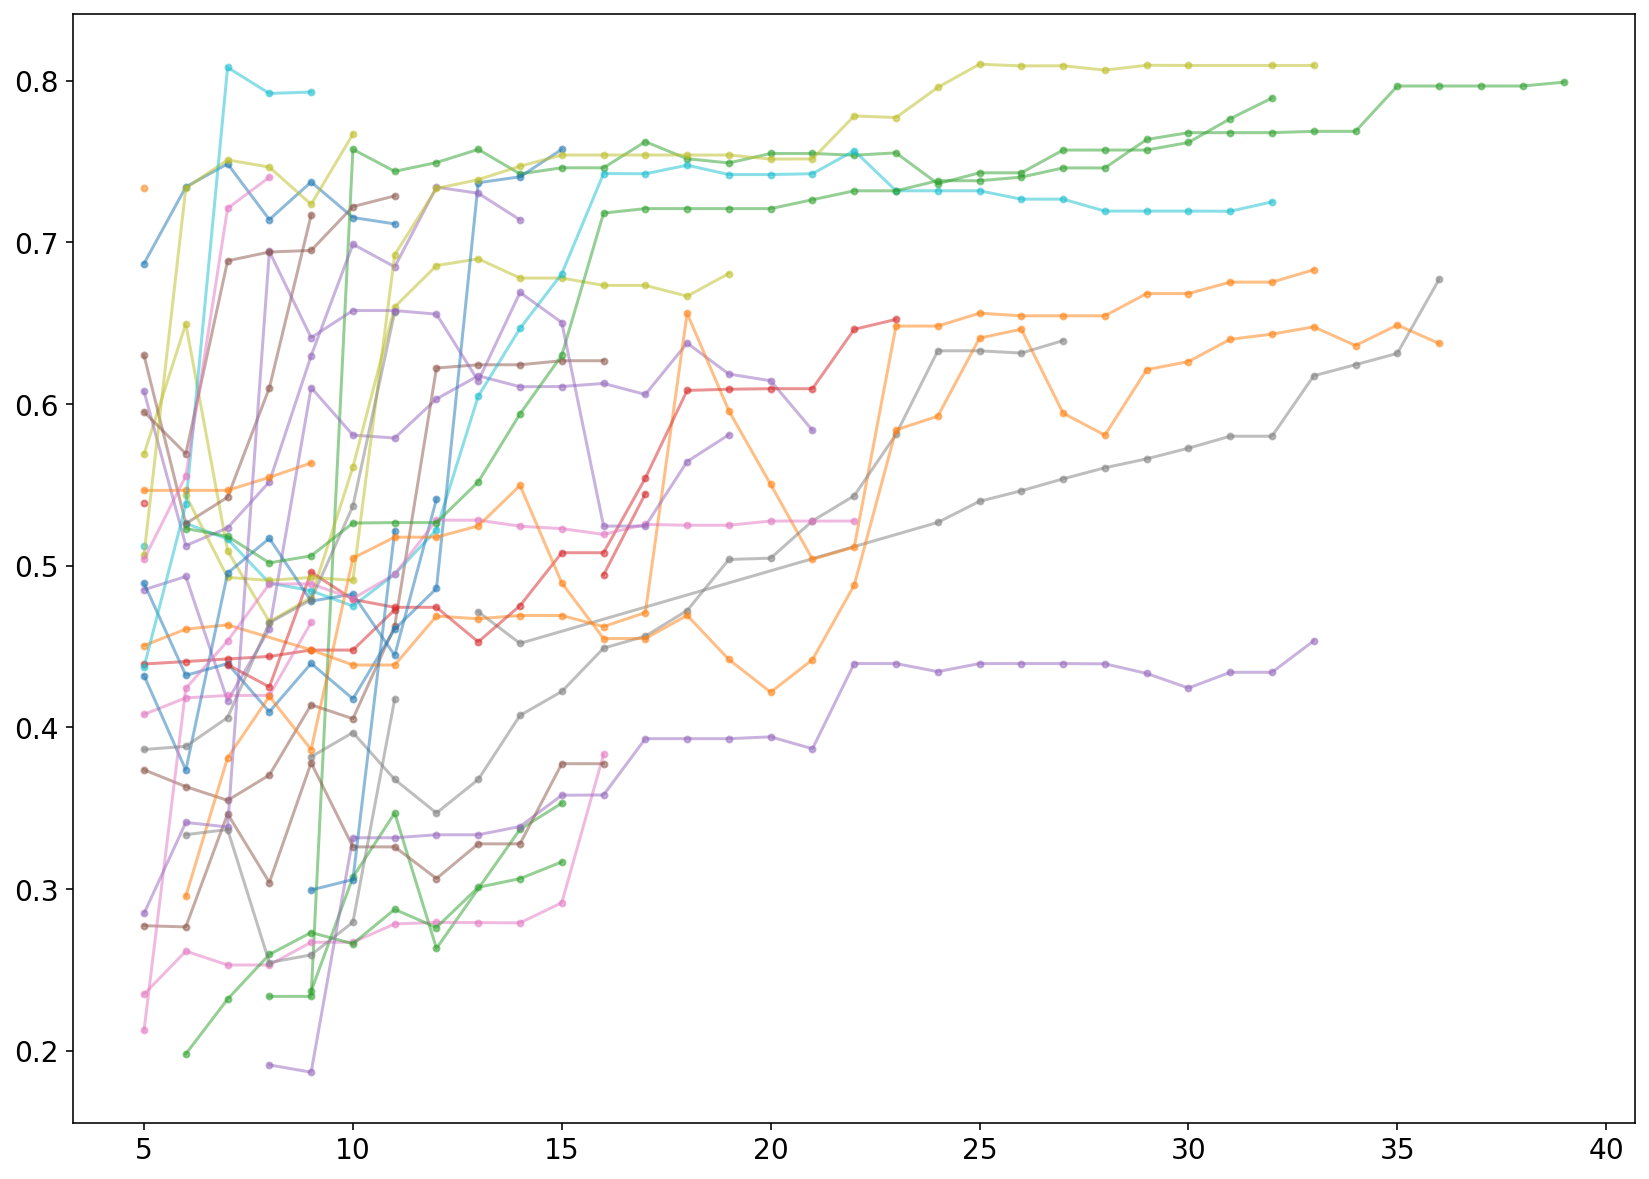

In [549]:
for oid in np.unique(features[good_idx & tde_idx]['objectId']):
    idx = features['objectId']==oid
    aidx = np.argsort(features['num_detections'][idx])
    plt.plot(features['num_detections'][idx][aidx], tde_score_proba[idx][aidx], '.-', alpha=0.5)
#     break

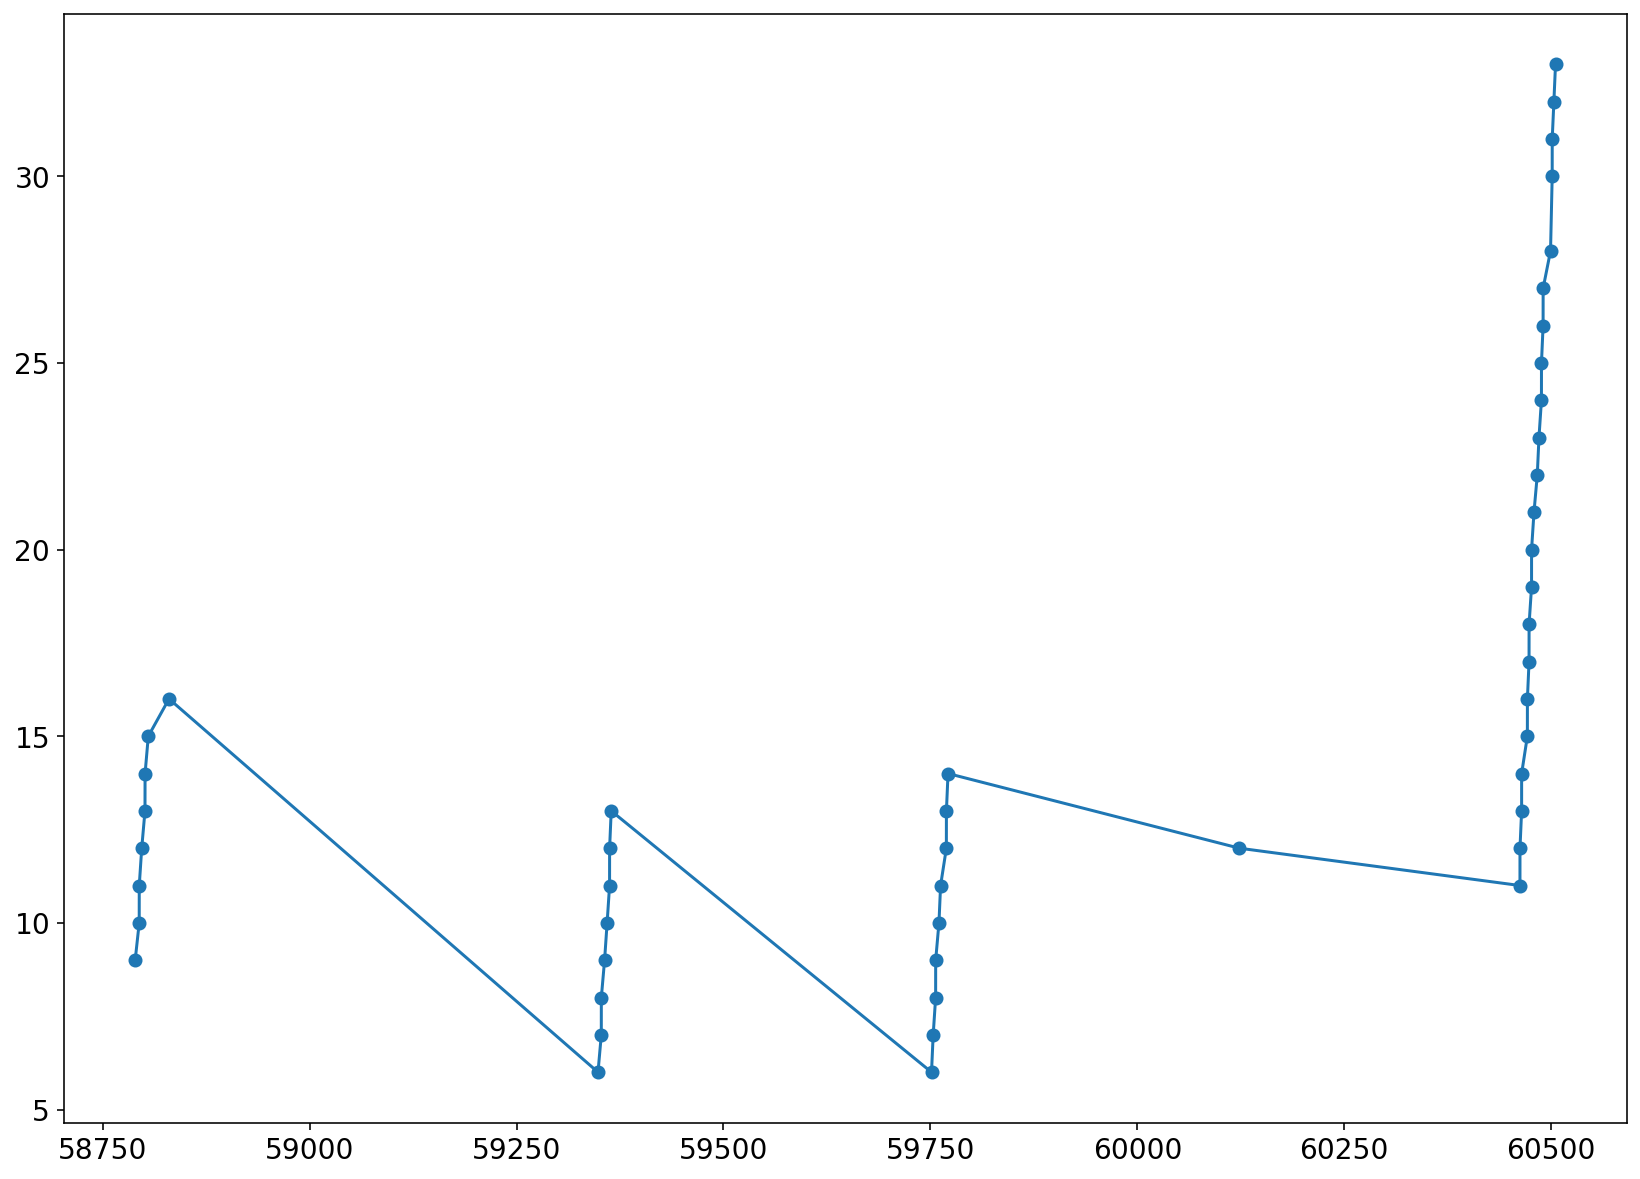

In [513]:
idx = features['objectId']=='ZTF18adcbgey'
aidx = np.argsort(features['jd_max'][idx])
# plt.plot(features['jd_max'][idx][aidx]-2400000.5, tde_score[idx][aidx], 'o-')
plt.plot(features['jd_max'][idx][aidx]-2400000.5, features['num_detections'][idx][aidx], 'o-')

In [515]:
idx2 = features['jd_max'][idx]-2400000.5 > 60400
np.min(features['num_detections'][idx][idx2])

np.int64(11)

In [ ]:
for oid in np.unique(features[good_idx & tde_idx]['objectId']):
    idx = features['objectId']==oid
    aidx = np.argsort(features['num_detections'][idx])
    plt.plot(features['num_detections'][idx][aidx], tde_score_proba[idx][aidx], '.-', alpha=0.5)
#     break

In [253]:
from dustmaps.sfd import SFDQuery

sfd = SFDQuery()

v1,v2,v3 = [],[],[]

# for cand in tqdm(features[good_idx & tde_idx]):
for cand in tqdm(features[tns_all_idx & good_idx & (features['pcounter']==0)]):
#     sub = data[data['objectId'] == cand['objectId']].iloc[0]    
#     Ebv = sfd(SkyCoord(sub['i:ra'], sub['i:dec'], unit='deg'))
    Ebv = cand['Ebv']
    
    v1.append(cand['temperature'])
    v2.append(Ebv)
    
    v3.append(cand['objectId'] in features['objectId'][tde_idx])
    
#     print(cand['objectId'], cand['tns_name'], cand['temperature'], Ebv)
    pass

  0%|          | 0/8866 [00:00<?, ?it/s]

In [258]:
np.array(v3)

array([False, False, False, ..., False, False, False], shape=(8866,))

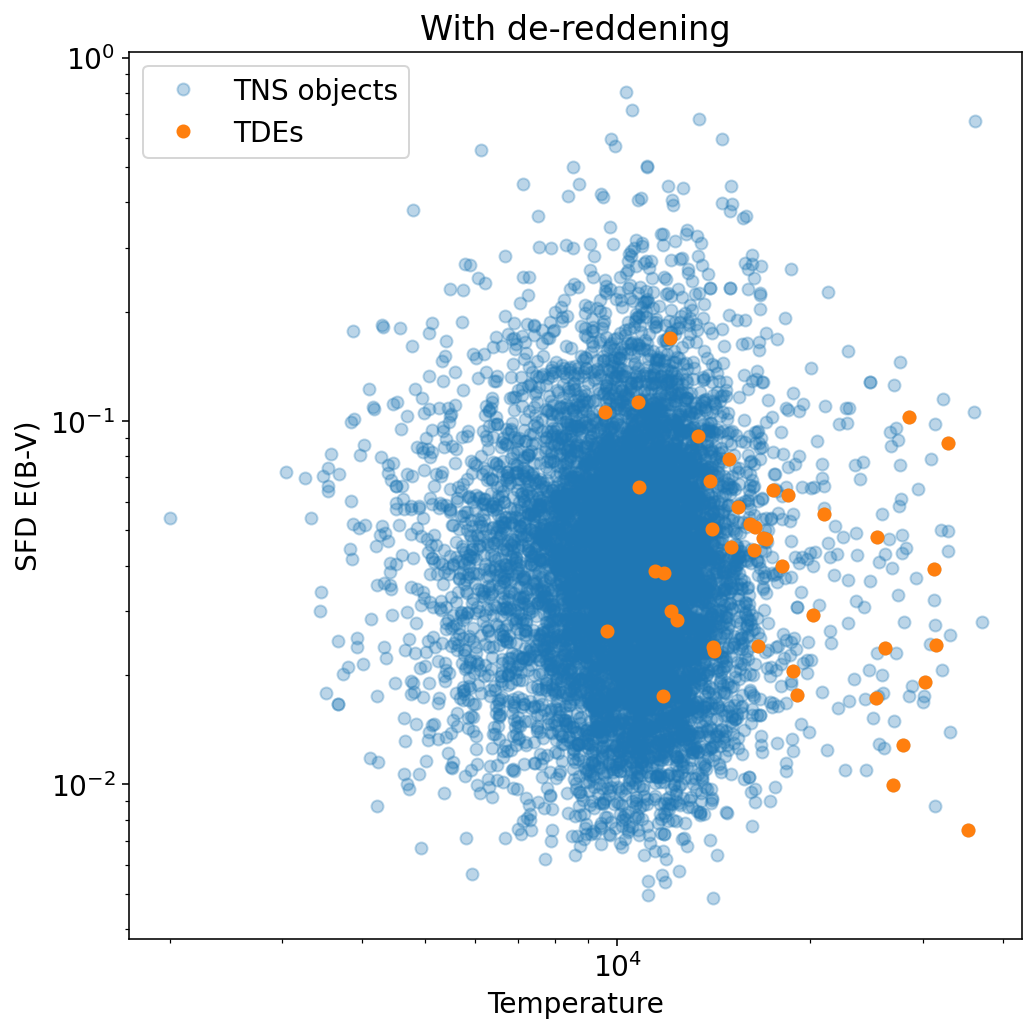

In [260]:
plt.figure(figsize=(8,8))
plt.plot(v1, v2, 'o', alpha=0.3, label='TNS objects')

idx = np.array(v3) == True
plt.plot(np.array(v1)[idx], np.array(v2)[idx], 'o', alpha=1, label='TDEs')

plt.xscale('log')
plt.yscale('log')
# plt.xlim(None, 1e4)
plt.xlabel('Temperature')
plt.ylabel('SFD E(B-V)')
plt.title('With de-reddening')
plt.legend()